**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso:** MLOPs TC5061

Tecnológico de Monterrey

**Alumno** Cristhian Rikardo Hernandez Hernandez

**Docente** Dr. Iván Reyes Amezcua

**Actividad**
Dataset - Notebook | Individual


---

### Paso 1: Carga y describe el dataset:

Importa los datos en un notebook.

Describe su estructura (número de registros, variables, tipos y significado).

In [ ]:
from ucimlrepo import fetch_ucirepo 
  
# Obteniendo dataset de UCI Machine Learning Repository
cdc_diabetes_health_indicators = fetch_ucirepo(id=891) 
  
# Colocando los datos en variables
X = cdc_diabetes_health_indicators.data.features 
y = cdc_diabetes_health_indicators.data.targets 
  
# metadata information 
print(cdc_diabetes_health_indicators.metadata) 
  
# variable information 
print(cdc_diabetes_health_indicators.variables) 


{'uci_id': 891, 'name': 'CDC Diabetes Health Indicators', 'repository_url': 'https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators', 'data_url': 'https://archive.ics.uci.edu/static/public/891/data.csv', 'abstract': 'The Diabetes Health Indicators Dataset contains healthcare statistics and lifestyle survey information about people in general along with their diagnosis of diabetes. The 35 features consist of some demographics, lab test results, and answers to survey questions for each patient. The target variable for classification is whether a patient has diabetes, is pre-diabetic, or healthy. ', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Tabular', 'Multivariate'], 'num_instances': 253680, 'num_features': 21, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Sex', 'Age', 'Education Level', 'Income'], 'target_col': ['Diabetes_binary'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_

In [30]:
import pandas as pd

# Unimos variables predictoras y objetivo en un solo DataFrame
df = pd.concat([X, y], axis=1)

print(f"Número de registros: {df.shape[0]:,}")
print(f"Número de variables: {df.shape[1]} ({X.shape[1]} predictoras + {y.shape[1]} objetivo)")
print(f"Valores faltantes totales: {df.isna().sum().sum()}")
print()

# Resumen de estructura: tipo de dato, valores únicos y rango de cada variable
estructura = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "min": df.min(),
    "max": df.max(),
})
estructura

# Distribución de la variable objetivo
# df["Diabetes_binary"].value_counts(normalize=True)

Número de registros: 253,680
Número de variables: 22 (21 predictoras + 1 objetivo)
Valores faltantes totales: 0



,tipo_pandas,valores_unicos,min,max
HighBP,int64,2,0,1
HighChol,int64,2,0,1
CholCheck,int64,2,0,1
BMI,int64,84,12,98
Smoker,int64,2,0,1
Stroke,int64,2,0,1
HeartDiseaseorAttack,int64,2,0,1
PhysActivity,int64,2,0,1
Fruits,int64,2,0,1
Veggies,int64,2,0,1


### Descripción del dataset: *CDC Diabetes Health Indicators* (UCI id 891)

**Fuente:** Encuesta BRFSS 2014 de los CDC (Centers for Disease Control and Prevention, EE. UU.). Cada fila representa a una persona encuestada.

**Estructura general**

| Característica | Valor |
|---|---|
| Número de registros | **253,680** |
| Número de variables | **22** (21 predictoras + 1 objetivo) |
| Tipo de dato en pandas | Todas `int64` |
| Valores faltantes | Ninguno |
| Tipo de problema | Clasificación binaria |
| Balance de la variable objetivo | 86.1 % sin diabetes (0) · 13.9 % prediabetes/diabetes (1) → **desbalanceado** |

**Variables, tipo y significado**

| # | Variable | Rol | Tipo | Rango | Significado |
|---|---|---|---|---|---|
| 1 | `Diabetes_binary` | Objetivo | Binaria | 0–1 | 0 = sin diabetes, 1 = prediabetes o diabetes |
| 2 | `HighBP` | Predictora | Binaria | 0–1 | Presión arterial alta (1 = sí) |
| 3 | `HighChol` | Predictora | Binaria | 0–1 | Colesterol alto (1 = sí) |
| 4 | `CholCheck` | Predictora | Binaria | 0–1 | Se revisó el colesterol en los últimos 5 años (1 = sí) |
| 5 | `BMI` | Predictora | Entera (numérica continua) | 12–98 | Índice de masa corporal |
| 6 | `Smoker` | Predictora | Binaria | 0–1 | Ha fumado al menos 100 cigarrillos en su vida (1 = sí) |
| 7 | `Stroke` | Predictora | Binaria | 0–1 | Alguna vez le diagnosticaron un derrame cerebral (1 = sí) |
| 8 | `HeartDiseaseorAttack` | Predictora | Binaria | 0–1 | Enfermedad coronaria o infarto al miocardio (1 = sí) |
| 9 | `PhysActivity` | Predictora | Binaria | 0–1 | Actividad física en los últimos 30 días, sin contar el trabajo (1 = sí) |
| 10 | `Fruits` | Predictora | Binaria | 0–1 | Consume fruta 1 o más veces al día (1 = sí) |
| 11 | `Veggies` | Predictora | Binaria | 0–1 | Consume verduras 1 o más veces al día (1 = sí) |
| 12 | `HvyAlcoholConsump` | Predictora | Binaria | 0–1 | Consumo alto de alcohol (hombres >14 bebidas/semana, mujeres >7) (1 = sí) |
| 13 | `AnyHealthcare` | Predictora | Binaria | 0–1 | Cuenta con algún tipo de seguro/cobertura médica (1 = sí) |
| 14 | `NoDocbcCost` | Predictora | Binaria | 0–1 | En los últimos 12 meses no pudo ir al médico por el costo (1 = sí) |
| 15 | `GenHlth` | Predictora | Ordinal | 1–5 | Salud general autopercibida: 1 = excelente … 5 = mala |
| 16 | `MentHlth` | Predictora | Entera (conteo) | 0–30 | Días con mala salud mental en los últimos 30 días |
| 17 | `PhysHlth` | Predictora | Entera (conteo) | 0–30 | Días con mala salud física en los últimos 30 días |
| 18 | `DiffWalk` | Predictora | Binaria | 0–1 | Dificultad seria para caminar o subir escaleras (1 = sí) |
| 19 | `Sex` | Predictora (demográfica) | Binaria | 0–1 | 0 = mujer, 1 = hombre |
| 20 | `Age` | Predictora (demográfica) | Ordinal | 1–13 | Categoría de edad en rangos de 5 años: 1 = 18–24 … 9 = 60–64 … 13 = 80 o más |
| 21 | `Education` | Predictora (demográfica) | Ordinal | 1–6 | Nivel educativo: 1 = nunca asistió a la escuela … 6 = 4+ años de universidad |
| 22 | `Income` | Predictora (demográfica) | Ordinal | 1–8 | Ingreso anual: 1 = menos de \$10,000 … 8 = \$75,000 o más |

**Observaciones**
- Aunque pandas almacena todo como `int64`, la mayoría de las variables son **categóricas codificadas**: 14 binarias, 4 ordinales (`GenHlth`, `Age`, `Education`, `Income`) y solo 3 numéricas propiamente dichas (`BMI`, `MentHlth`, `PhysHlth`).
- La columna `ID` aparece en los metadatos pero no se incluye en `X`, por lo que no hay que eliminarla.
- El desbalance de clases (≈86/14) debe tomarse en cuenta al elegir métricas (p. ej. F1, recall o ROC-AUC en lugar de solo *accuracy*).
- `Sex`, `Income` y `Education` son atributos sensibles según los metadatos del dataset.

## Paso 2: Realiza un análisis exploratorio (EDA):

Genera estadísticas descriptivas y visualizaciones que te permitan entender la distribución de las variables y las relaciones entre ellas.

In [ ]:
# Estadísticas descriptivas básicas de todas las variables (transpuesta para leerla por fila)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0


### 2.1 Configuración del análisis

Agrupamos las variables según su **tipo real** (no según el `int64` de pandas), porque cada tipo requiere estadísticas y gráficos distintos:

- **Numéricas** (`BMI`, `MentHlth`, `PhysHlth`): media, mediana, dispersión, asimetría, outliers → histogramas y boxplots.
- **Binarias** (14 variables 0/1): la media es directamente la **prevalencia** (% de personas con valor 1).
- **Ordinales** (`GenHlth`, `Age`, `Education`, `Income`): frecuencias por nivel.

Colores fijos en todo el EDA: **azul = sin diabetes (0)** y **naranja = prediabetes/diabetes (1)**.

In [32]:
# Librerías para cálculo y visualización
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# Clasificación de las variables según su tipo real
TARGET = "Diabetes_binary"
NUMERICAS = ["BMI", "MentHlth", "PhysHlth"]
ORDINALES = ["GenHlth", "Age", "Education", "Income"]
BINARIAS = [c for c in df.columns if c not in NUMERICAS + ORDINALES + [TARGET]]

# Paleta consistente para todo el EDA
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"
PALETA_CLASE = {0: AZUL, 1: NARANJA}
ETIQUETA_CLASE = {0: "Sin diabetes (0)", 1: "Prediabetes/diabetes (1)"}
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list("azul_rojo", ["#104281", AZUL, "#f0efec", "#e34948", "#9b1c1c"])
CMAP_SECUENCIAL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])

# Estilo general de las gráficas
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "figure.dpi": 100,
})

# Tasa global de diabetes, se usa como referencia en varias gráficas
TASA_GLOBAL = df[TARGET].mean()
print(f"Binarias ({len(BINARIAS)}): {BINARIAS}")
print(f"Ordinales ({len(ORDINALES)}): {ORDINALES}")
print(f"Numéricas ({len(NUMERICAS)}): {NUMERICAS}")
print(f"Tasa global de diabetes: {TASA_GLOBAL:.1%}")

Binarias (14): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Ordinales (4): ['GenHlth', 'Age', 'Education', 'Income']
Numéricas (3): ['BMI', 'MentHlth', 'PhysHlth']
Tasa global de diabetes: 13.9%


### 2.2 Variable objetivo: `Diabetes_binary`

Lo primero es confirmar el balance de clases, porque condiciona la elección de métricas y la estrategia de partición (estratificada).

,clase,registros,porcentaje
0,Sin diabetes (0),218334,86.07
1,Prediabetes/diabetes (1),35346,13.93


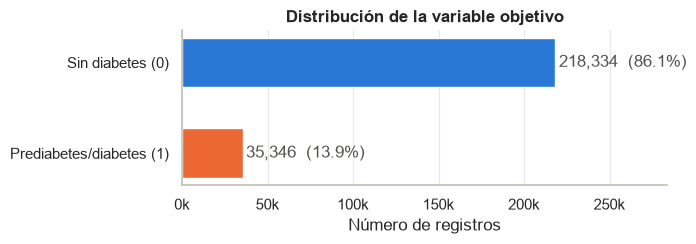

In [33]:
# Conteo y porcentaje de registros por clase
conteo = df[TARGET].value_counts().sort_index()
resumen_objetivo = pd.DataFrame({
    "clase": [ETIQUETA_CLASE[i] for i in conteo.index],
    "registros": conteo.values,
    "porcentaje": (conteo / len(df) * 100).round(2).values,
})
display(resumen_objetivo)

# Gráfica de barras horizontales con el tamaño de cada clase
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh([ETIQUETA_CLASE[i] for i in conteo.index], conteo.values,
        color=[PALETA_CLASE[i] for i in conteo.index], height=0.55)
# Etiqueta con el conteo y porcentaje al final de cada barra
for i, v in enumerate(conteo.values):
    ax.text(v + 2000, i, f"{v:,}  ({v / len(df):.1%})", va="center", color=GRIS)
ax.set_xlim(0, conteo.max() * 1.3)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("Número de registros")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 2.3 Estadísticas descriptivas de las variables numéricas

Además de `describe()`, calculamos **asimetría** (skew), **curtosis**, el **% de ceros** y el número de **outliers según la regla IQR** (valores fuera de Q1 − 1.5·IQR y Q3 + 1.5·IQR).

In [34]:
# Calcula estadísticas descriptivas extendidas para una variable numérica
def resumen_numerico(serie):
    # Límites de la regla IQR para detectar outliers
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((serie < lim_inf) | (serie > lim_sup)).sum()
    return pd.Series({
        "media": serie.mean(), "mediana": serie.median(), "moda": serie.mode()[0],
        "desv_std": serie.std(), "min": serie.min(), "Q1": q1, "Q3": q3, "max": serie.max(),
        "IQR": iqr, "asimetria": serie.skew(), "curtosis": serie.kurt(),
        "pct_ceros": (serie == 0).mean() * 100,
        "lim_sup_IQR": lim_sup, "n_outliers_IQR": outliers,
        "pct_outliers_IQR": outliers / len(serie) * 100,
    })

# Aplica el resumen a cada variable numérica
desc_numericas = df[NUMERICAS].apply(resumen_numerico).T.round(2)
desc_numericas

,media,mediana,moda,desv_std,min,Q1,Q3,max,IQR,asimetria,curtosis,pct_ceros,lim_sup_IQR,n_outliers_IQR,pct_outliers_IQR
BMI,28.38,27.0,27.0,6.61,12.0,24.0,31.0,98.0,7.0,2.12,11.00,0.00,41.5,9847.0,3.88
MentHlth,3.18,0.0,0.0,7.41,0.0,0.0,2.0,30.0,2.0,2.72,6.44,69.25,5.0,36208.0,14.27
PhysHlth,4.24,0.0,0.0,8.72,0.0,0.0,3.0,30.0,3.0,2.21,3.50,63.09,7.5,40949.0,16.14


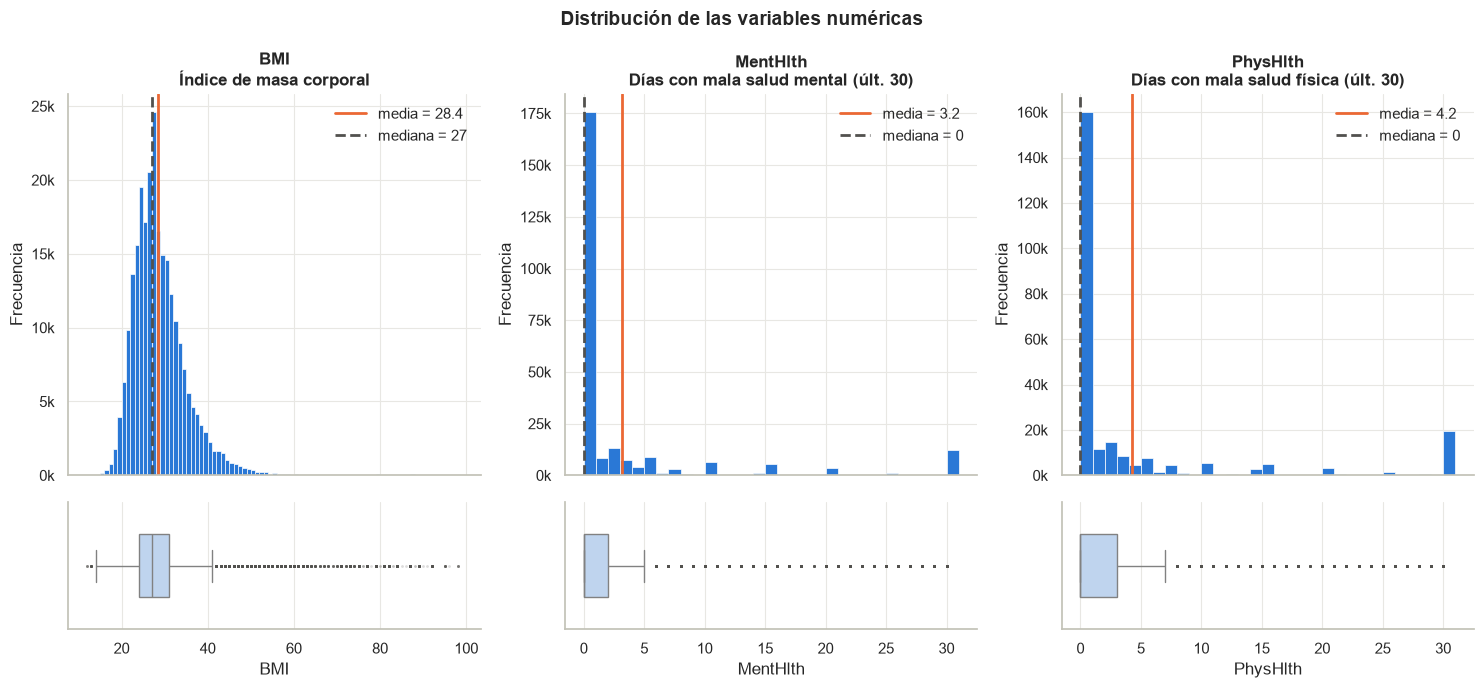

In [35]:
# Cuadrícula: histogramas arriba y boxplots abajo, una columna por variable
fig, axes = plt.subplots(2, 3, figsize=(15, 7), gridspec_kw={"height_ratios": [3, 1]}, sharex="col")
bins = {"BMI": np.arange(12, 100, 1), "MentHlth": np.arange(0, 32, 1), "PhysHlth": np.arange(0, 32, 1)}
nombres = {"BMI": "Índice de masa corporal", "MentHlth": "Días con mala salud mental (últ. 30)",
           "PhysHlth": "Días con mala salud física (últ. 30)"}

for j, col in enumerate(NUMERICAS):
    # Histograma con líneas de media y mediana
    ax = axes[0, j]
    ax.hist(df[col], bins=bins[col], color=AZUL, edgecolor="white", linewidth=0.5)
    ax.axvline(df[col].mean(), color=NARANJA, lw=2, label=f"media = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color=GRIS, lw=2, ls="--", label=f"mediana = {df[col].median():.0f}")
    ax.set_title(f"{col}\n{nombres[col]}")
    ax.set_ylabel("Frecuencia")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
    ax.legend(frameon=False)

    # Boxplot para visualizar dispersión y outliers
    sns.boxplot(x=df[col], ax=axes[1, j], color="#b7d3f6", width=0.5, linewidth=1,
                flierprops=dict(marker="o", markersize=2, alpha=0.2, markerfacecolor=GRIS, markeredgecolor="none"))
    axes[1, j].set_xlabel(col)

plt.suptitle("Distribución de las variables numéricas", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

### 2.4 Variables binarias: prevalencia

Para una variable 0/1 la media es la proporción de personas que responden "sí". Comparamos la prevalencia en la población total.

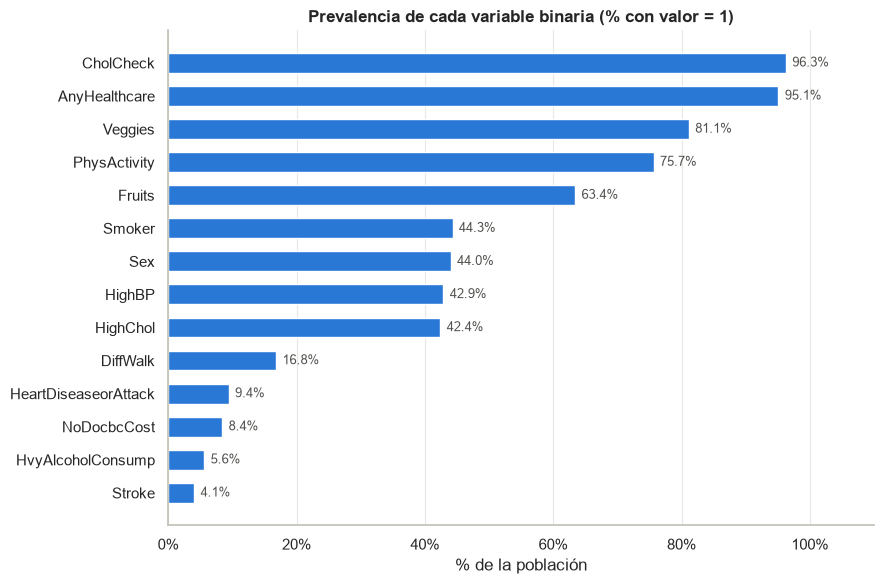

In [36]:
# Prevalencia = % de registros con valor 1 en cada variable binaria
prevalencia = (df[BINARIAS].mean() * 100).sort_values()

# Gráfica de barras horizontales ordenada de menor a mayor
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(prevalencia.index, prevalencia.values, color=AZUL, height=0.6)
for i, v in enumerate(prevalencia.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", color=GRIS, fontsize=9)
ax.set_xlim(0, 110)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Prevalencia de cada variable binaria (% con valor = 1)")
ax.set_xlabel("% de la población")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 2.5 Variables ordinales: distribución por nivel

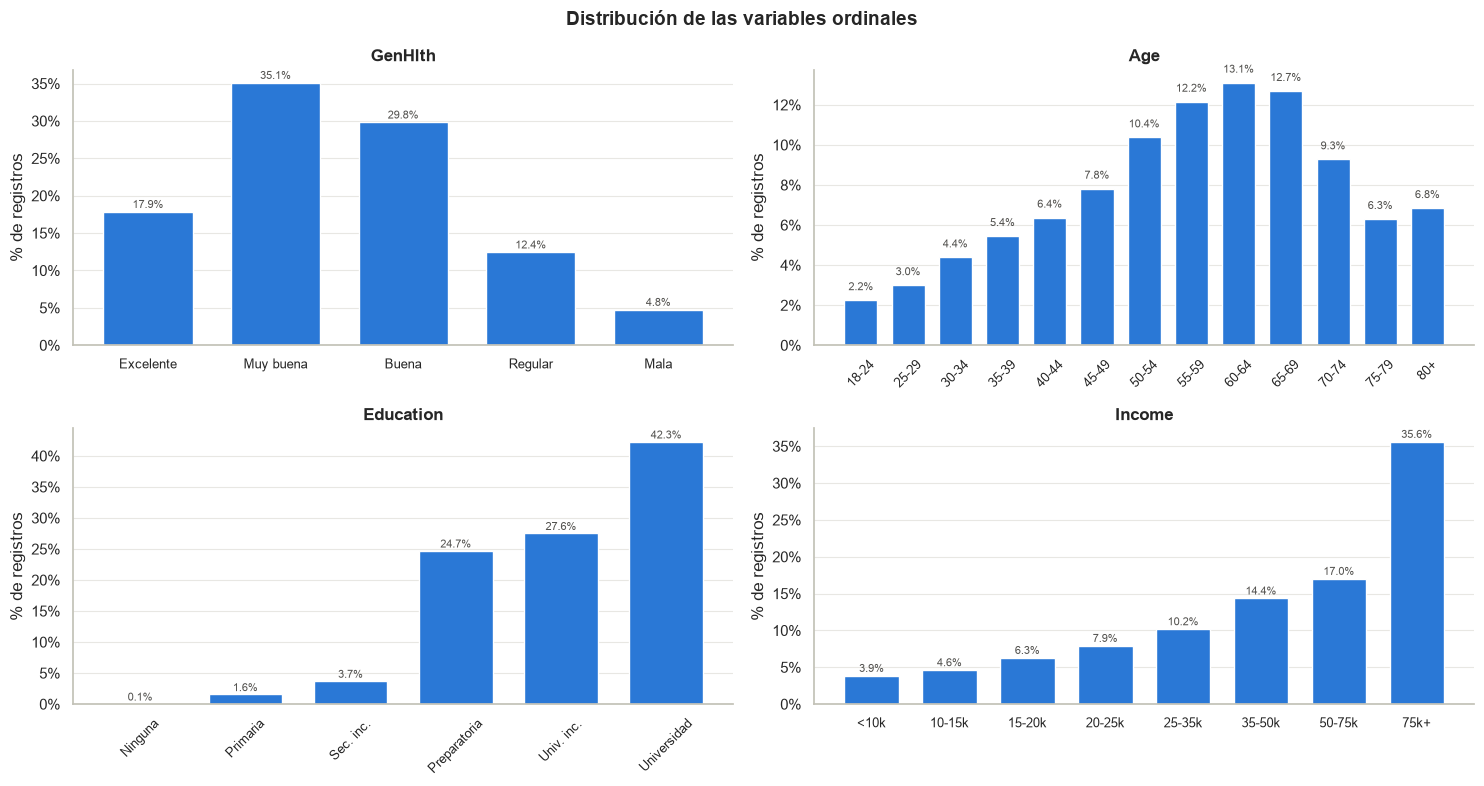

In [37]:
# Etiquetas legibles para cada nivel de las variables ordinales
etiquetas_ordinales = {
    "GenHlth": {1: "Excelente", 2: "Muy buena", 3: "Buena", 4: "Regular", 5: "Mala"},
    "Age": {1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44", 6: "45-49", 7: "50-54",
            8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"},
    "Education": {1: "Ninguna", 2: "Primaria", 3: "Sec. inc.", 4: "Preparatoria", 5: "Univ. inc.", 6: "Universidad"},
    "Income": {1: "<10k", 2: "10-15k", 3: "15-20k", 4: "20-25k", 5: "25-35k", 6: "35-50k", 7: "50-75k", 8: "75k+"},
}

# Una gráfica de barras por variable con el % de registros en cada nivel
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, col in zip(axes.flat, ORDINALES):
    pct = df[col].value_counts(normalize=True).sort_index() * 100
    etiquetas = [etiquetas_ordinales[col][k] for k in pct.index]
    ax.bar(etiquetas, pct.values, color=AZUL, width=0.7)
    for x, v in enumerate(pct.values):
        ax.text(x, v + 0.5, f"{v:.1f}%", ha="center", color=GRIS, fontsize=8)
    ax.set_title(col)
    ax.set_ylabel("% de registros")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.tick_params(axis="x", rotation=45 if col in ("Age", "Education") else 0, labelsize=9)
    ax.grid(axis="x", visible=False)
plt.suptitle("Distribución de las variables ordinales", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## Relaciones entre variables

### 2.6 Variables numéricas vs. variable objetivo

In [38]:
# Media, mediana y desviación estándar de cada variable numérica por clase
df.groupby(TARGET)[NUMERICAS].agg(["mean", "median", "std"]).T.rename(columns=ETIQUETA_CLASE).round(2)

Diabetes_binary  Sin diabetes (0)  Prediabetes/diabetes (1)
BMI      mean               27.81                     31.94
         median             27.00                     31.00
         std                 6.29                      7.36
MentHlth mean                2.98                      4.46
         median              0.00                      0.00
         std                 7.11                      8.95
PhysHlth mean                3.64                      7.95
         median              0.00                      1.00
         std                 8.06                     11.30

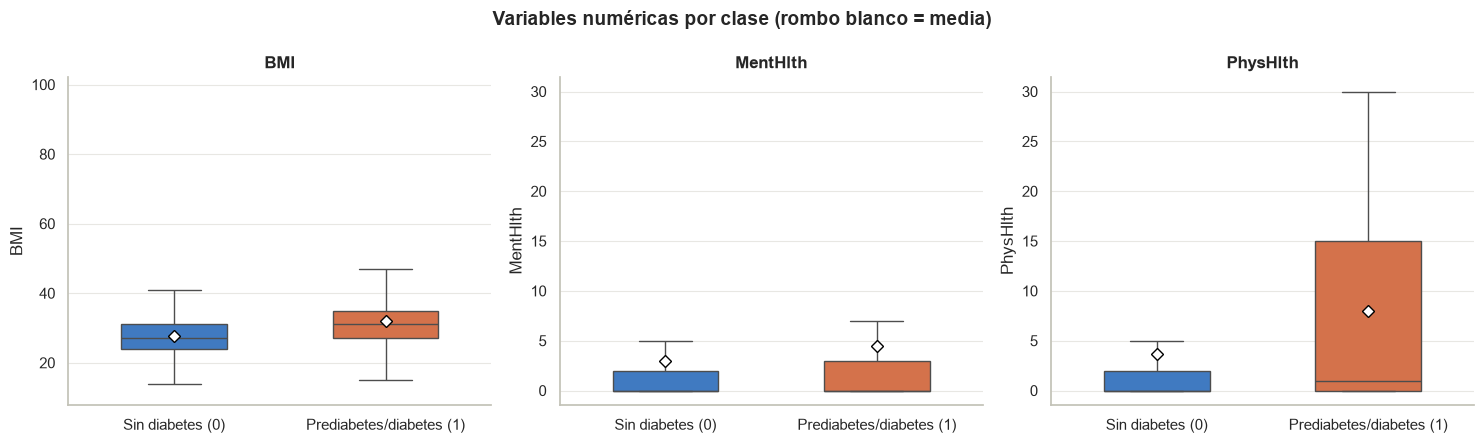

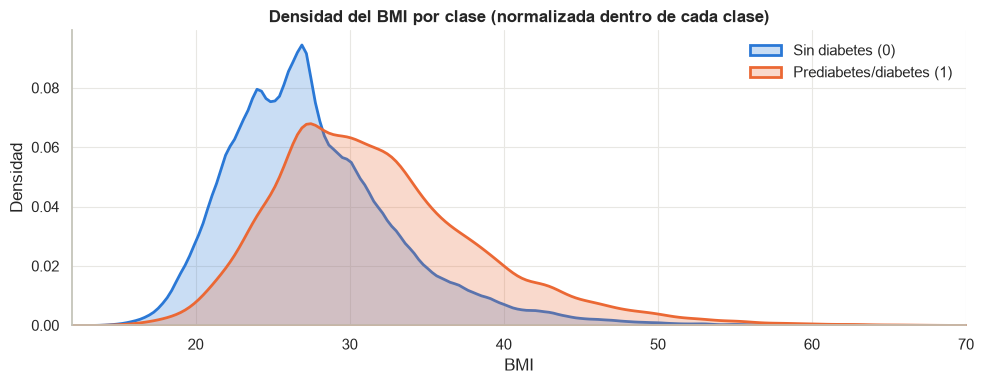

In [39]:
# Boxplots de cada variable numérica separados por clase (el rombo blanco marca la media)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, NUMERICAS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=PALETA_CLASE, ax=ax, legend=False,
                width=0.5, linewidth=1, showmeans=True,
                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6),
                flierprops=dict(marker="o", markersize=2, alpha=0.15, markeredgecolor="none"))
    ax.set_xticks([0, 1], [ETIQUETA_CLASE[0], ETIQUETA_CLASE[1]])
    ax.set_xlabel("")
    ax.set_title(col)
plt.suptitle("Variables numéricas por clase (rombo blanco = media)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

# Densidad del BMI por clase: muestra el desplazamiento de toda la distribución, no solo de la mediana
fig, ax = plt.subplots(figsize=(10, 4))
for clase in (0, 1):
    sns.kdeplot(df.loc[df[TARGET] == clase, "BMI"], ax=ax, color=PALETA_CLASE[clase],
                fill=True, alpha=0.25, linewidth=2, label=ETIQUETA_CLASE[clase], clip=(12, 70))
ax.set_xlim(12, 70)
ax.set_ylabel("Densidad")
ax.set_title("Densidad del BMI por clase (normalizada dentro de cada clase)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 2.7 Variables binarias vs. variable objetivo

Para cada factor binario comparamos la **tasa de diabetes** entre quienes tienen el factor (=1) y quienes no (=0). El cociente entre ambas es el **riesgo relativo (RR)**: RR > 1 indica asociación positiva con diabetes, RR < 1 asociación negativa.

,tasa_si_0,tasa_si_1,riesgo_relativo
variable,,,
CholCheck,2.54,14.37,5.65
HighBP,6.04,24.45,4.05
DiffWalk,10.53,30.75,2.92
HighChol,7.98,22.01,2.76
HeartDiseaseorAttack,11.95,32.97,2.76
Stroke,13.18,31.75,2.41
Smoker,12.06,16.29,1.35
NoDocbcCost,13.60,17.52,1.29
AnyHealthcare,11.45,14.06,1.23


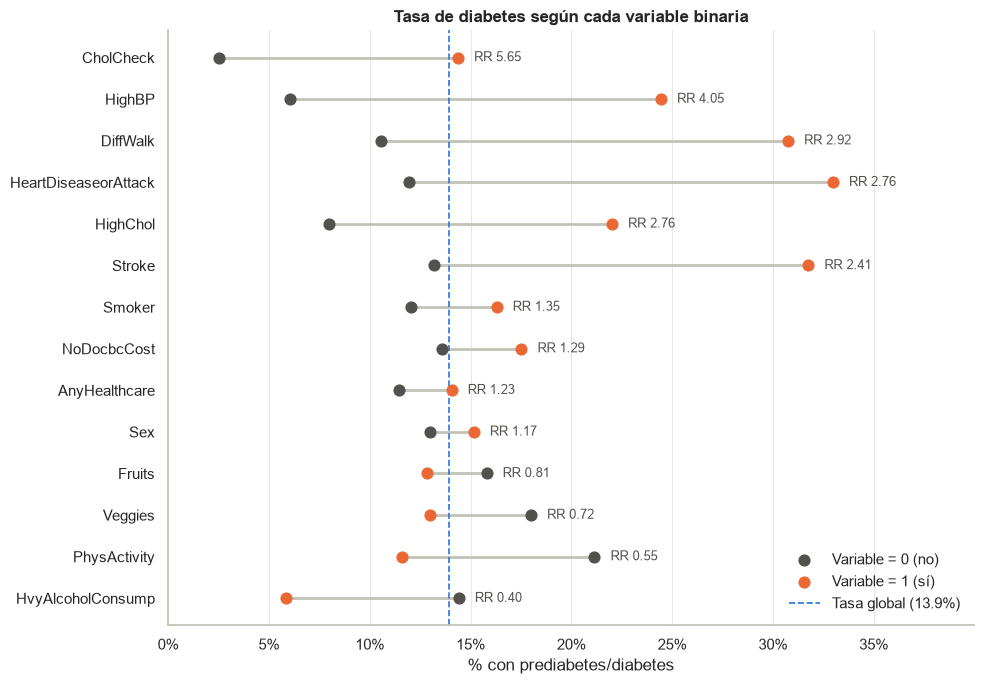

In [40]:
# Tasa de diabetes cuando cada variable binaria vale 0 y cuando vale 1, y su riesgo relativo
filas = []
for col in BINARIAS:
    tasas = df.groupby(col)[TARGET].mean()
    filas.append({"variable": col, "tasa_si_0": tasas[0] * 100, "tasa_si_1": tasas[1] * 100,
                  "riesgo_relativo": tasas[1] / tasas[0]})
tasas_binarias = pd.DataFrame(filas).set_index("variable").sort_values("riesgo_relativo")
display(tasas_binarias.round(2).sort_values("riesgo_relativo", ascending=False))

# Gráfico de "mancuernas": cada fila une la tasa con factor=0 y factor=1
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(tasas_binarias))
ax.hlines(y, tasas_binarias["tasa_si_0"], tasas_binarias["tasa_si_1"], color="#c3c2b7", lw=2)
ax.scatter(tasas_binarias["tasa_si_0"], y, color=GRIS, s=60, zorder=3, label="Variable = 0 (no)")
ax.scatter(tasas_binarias["tasa_si_1"], y, color=NARANJA, s=60, zorder=3, label="Variable = 1 (sí)")
# Etiqueta con el riesgo relativo a la derecha de cada fila
for yi, (_, r) in zip(y, tasas_binarias.iterrows()):
    ax.text(max(r["tasa_si_0"], r["tasa_si_1"]) + 0.8, yi, f"RR {r['riesgo_relativo']:.2f}",
            va="center", fontsize=9, color=GRIS)
# Línea de referencia con la tasa global
ax.axvline(TASA_GLOBAL * 100, color=AZUL, ls="--", lw=1.2, label=f"Tasa global ({TASA_GLOBAL:.1%})")
ax.set_yticks(y, tasas_binarias.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, tasas_binarias[["tasa_si_0", "tasa_si_1"]].max().max() + 7)
ax.set_xlabel("% con prediabetes/diabetes")
ax.set_title("Tasa de diabetes según cada variable binaria")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 2.8 Variables ordinales vs. variable objetivo

Tasa de diabetes en cada nivel. La línea punteada es la tasa global (≈13.9 %).

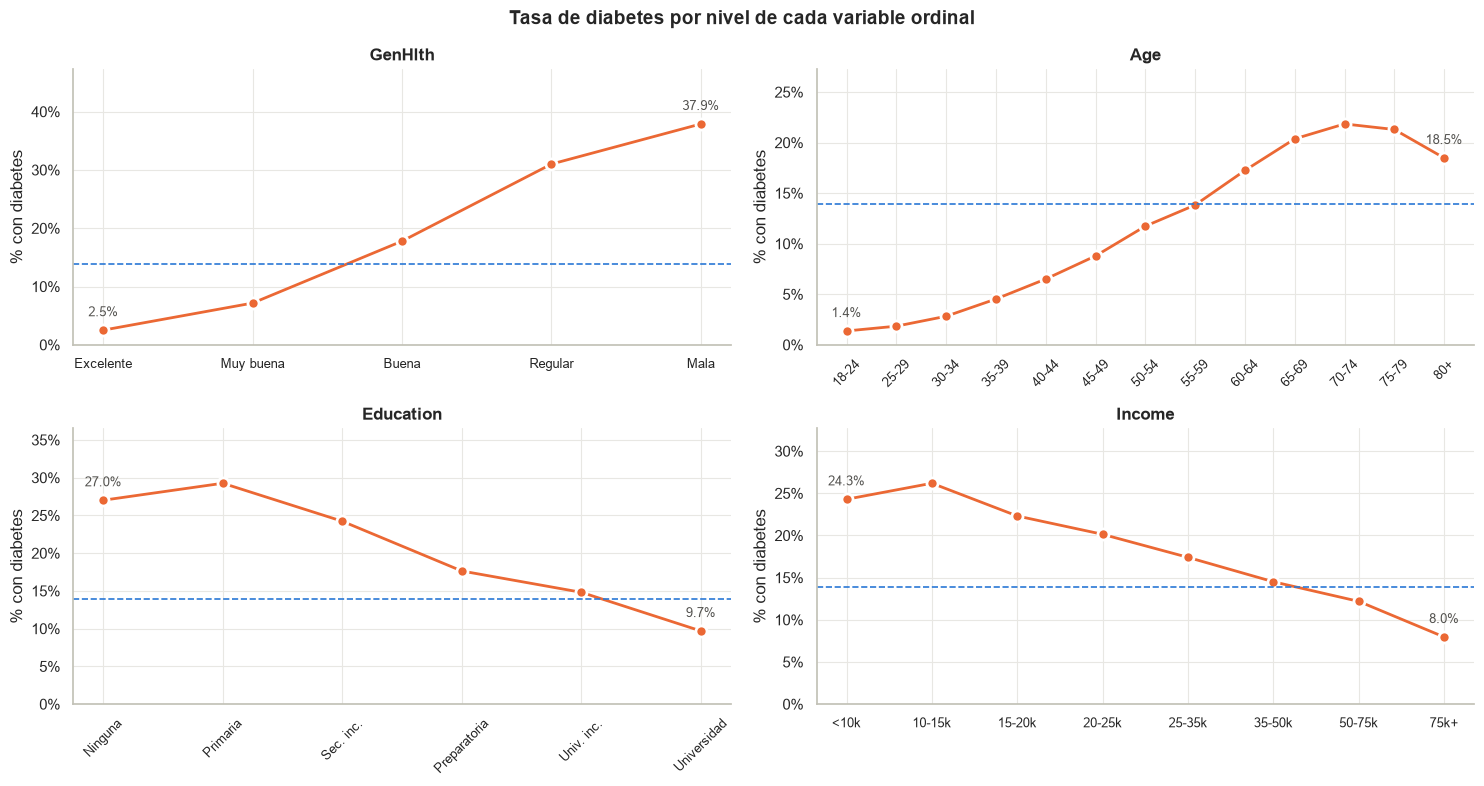

In [41]:
# Tasa de diabetes en cada nivel de las variables ordinales
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, col in zip(axes.flat, ORDINALES):
    tasa = df.groupby(col)[TARGET].mean() * 100
    etiquetas = [etiquetas_ordinales[col][k] for k in tasa.index]
    ax.plot(etiquetas, tasa.values, color=NARANJA, lw=2, marker="o", markersize=8,
            markeredgecolor="white", markeredgewidth=2)
    # Línea de referencia con la tasa global
    ax.axhline(TASA_GLOBAL * 100, color=AZUL, ls="--", lw=1.2)
    # Etiquetamos solo extremos para no saturar el gráfico
    for x in (0, len(tasa) - 1):
        ax.annotate(f"{tasa.values[x]:.1f}%", (x, tasa.values[x]), textcoords="offset points",
                    xytext=(0, 10), ha="center", fontsize=9, color=GRIS)
    ax.set_title(col)
    ax.set_ylabel("% con diabetes")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_ylim(0, tasa.max() * 1.25)
    ax.tick_params(axis="x", rotation=45 if col in ("Age", "Education") else 0, labelsize=9)
plt.suptitle("Tasa de diabetes por nivel de cada variable ordinal", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

,registros,tasa
BMI,,
Bajo peso <18.5,3127,5.40
Normal 18.5-25,68953,5.70
Sobrepeso 25-30,93749,11.40
Obesidad I 30-35,53451,19.23
Obesidad II 35-40,20663,27.44
Obesidad III 40+,13737,33.54


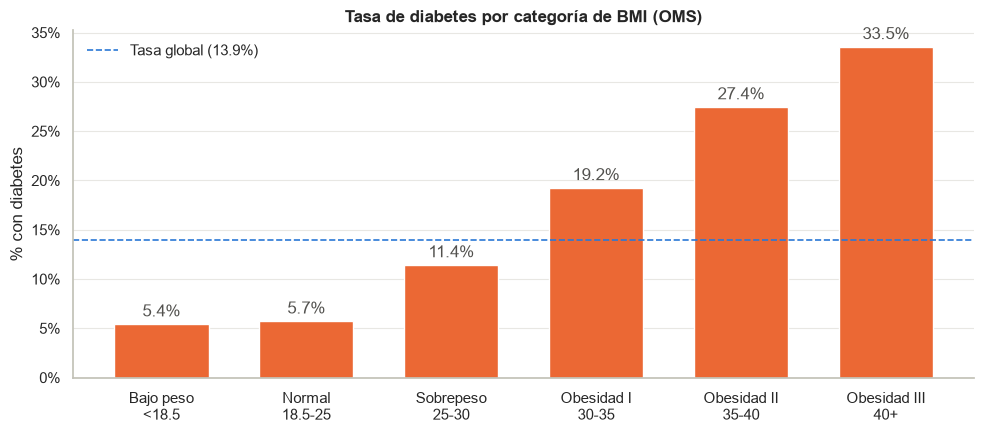

In [42]:
# BMI discretizado según categorías de la OMS: permite ver la relación como tasa y no solo como distribución
cortes = [0, 18.5, 25, 30, 35, 40, 100]
nombres_bmi = ["Bajo peso\n<18.5", "Normal\n18.5-25", "Sobrepeso\n25-30", "Obesidad I\n30-35",
               "Obesidad II\n35-40", "Obesidad III\n40+"]
bmi_cat = pd.cut(df["BMI"], bins=cortes, labels=nombres_bmi, right=False)

# Número de registros y tasa de diabetes por categoría
tabla_bmi = df.groupby(bmi_cat, observed=True)[TARGET].agg(registros="size", tasa="mean")
tabla_bmi["tasa"] *= 100
display(tabla_bmi.rename(index=lambda s: s.replace("\n", " ")).round(2))

# Gráfica de barras con la tasa por categoría y la tasa global como referencia
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(tabla_bmi.index.astype(str), tabla_bmi["tasa"], color=NARANJA, width=0.65)
for x, v in enumerate(tabla_bmi["tasa"]):
    ax.text(x, v + 0.8, f"{v:.1f}%", ha="center", color=GRIS)
ax.axhline(TASA_GLOBAL * 100, color=AZUL, ls="--", lw=1.2, label=f"Tasa global ({TASA_GLOBAL:.1%})")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("% con diabetes")
ax.set_title("Tasa de diabetes por categoría de BMI (OMS)")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 2.9 Matriz de correlación

Usamos la **correlación de Pearson (r)** para medir la fuerza y dirección de la relación lineal entre cada par de variables, incluida la variable objetivo. Aunque la mayoría de las variables son binarias u ordinales, Pearson sigue siendo interpretable en este caso: entre dos variables binarias equivale al **coeficiente phi** y entre una binaria y una numérica equivale a la **correlación punto-biserial**. Valores cercanos a 1 indican relación fuerte y cercanos a 0, relación lineal débil o nula.

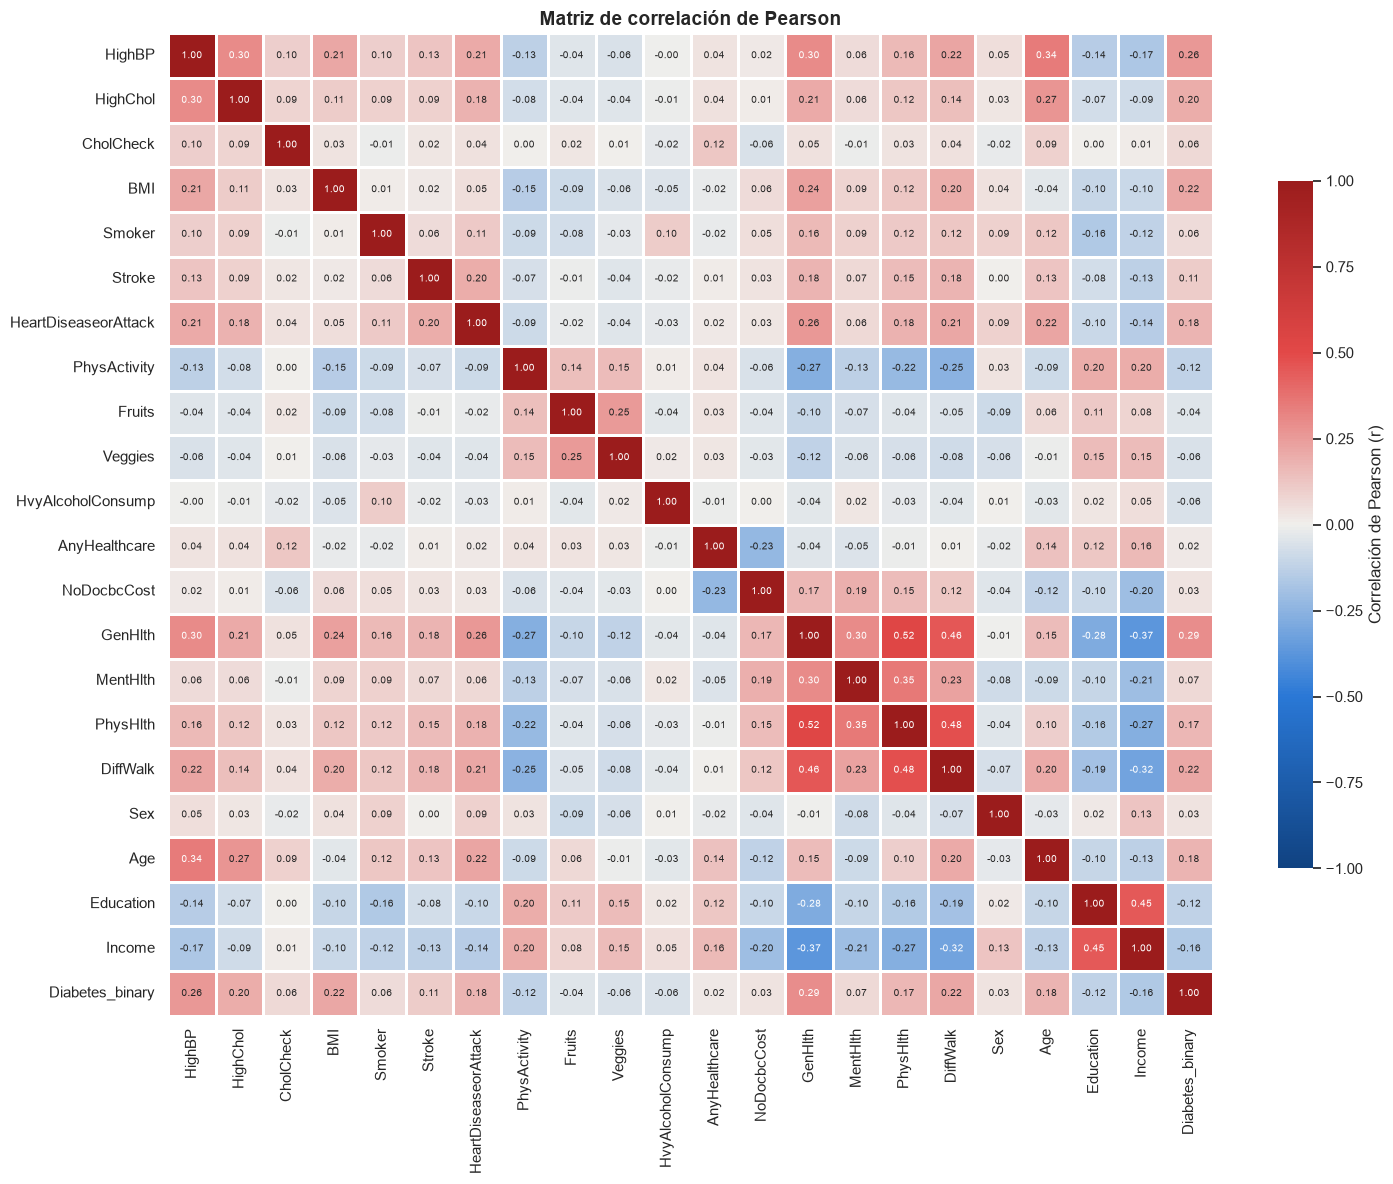

In [43]:
# Matriz de correlación de Pearson entre todas las variables
corr = df.corr(method="pearson")

# Mapa de calor: rojo = correlación positiva, azul = negativa
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(
    corr,
    cmap=CMAP_DIVERGENTE,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",  # Coeficiente con dos decimales (r va de -1 a 1, no es un porcentaje)
    annot_kws={"size": 7},
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Correlación de Pearson (r)", "shrink": 0.7},
    ax=ax,
)

ax.set_title("Matriz de correlación de Pearson", fontsize=14)
ax.grid(False)
plt.tight_layout()
plt.show()

### 2.10 Hallazgos principales del EDA

**Distribución de las variables**
- **Objetivo desbalanceado:** 86.1 % sin diabetes vs. 13.9 % con prediabetes/diabetes. En el modelado habrá que usar partición **estratificada** y métricas como recall, F1 o ROC-AUC; *accuracy* sola sería engañosa (un modelo que siempre predice 0 tendría 86 % de accuracy).
- **BMI:** media 28.4 y mediana 27 → la persona típica está en **sobrepeso**. Tiene sesgo a la derecha (asimetría 2.1, curtosis 11) y ~3.9 % de outliers por IQR (> 41.5), con máximos de 98 que son biológicamente improbables.
- **MentHlth y PhysHlth:** distribuciones muy concentradas en cero (69 % y 63 % de ceros) con un segundo pico en 30 días. La regla IQR marca 14–16 % de "outliers", pero **no son errores**: son respuestas válidas de personas con mala salud crónica, por lo que no conviene eliminarlas.
- **Binarias:** algunas están casi constantes — `CholCheck` (96 % = 1), `AnyHealthcare` (95 %), `HvyAlcoholConsump` (6 %) y `Stroke` (4 %) — y aportan poca variabilidad.
- **Ordinales:** la muestra está cargada hacia edades de 55–69 años, ingresos altos (la categoría modal es ≥ \$75k) y alta escolaridad.

**Relaciones con la variable objetivo**
- **Salud general (`GenHlth`)** es la predictora individual más correlacionada con el objetivo (r = 0.29): la tasa de diabetes pasa de **2.5 %** con salud "excelente" a **37.9 %** con salud "mala".
- **Presión alta (`HighBP`)**: 24.5 % de diabetes vs. 6.0 % sin ella (RR ≈ 4). `HighChol`, `DiffWalk`, `HeartDiseaseorAttack` y `Stroke` casi triplican el riesgo.
- **BMI:** relación monótona y fuerte: 5.7 % con peso normal → 33.5 % en obesidad III. La distribución completa del BMI en diabéticos está desplazada ~4 puntos a la derecha.
- **Edad:** la tasa crece de 1.4 % (18–24) a ~22 % (70–74) y baja ligeramente en 80+ (posible sesgo de supervivencia).
- **Factores socioeconómicos:** a mayor ingreso y escolaridad, menor tasa (ingreso < \$15k ≈ 25 % vs. ≥ \$75k = 8 %).
- **Factores protectores:** `PhysActivity` (RR 0.55), `Veggies` y `Fruits` se asocian con menor tasa. `HvyAlcoholConsump` también aparece como "protector" (RR 0.40), lo cual es contraintuitivo y probablemente refleja **confusión** (p. ej. edad o autoselección), no causalidad.
- `Sex`, `AnyHealthcare` y `NoDocbcCost` tienen una correlación prácticamente nula con el objetivo (|r| < 0.04), y `MentHlth` muy débil (r = 0.07).

**Relaciones entre predictoras**
- Las correlaciones más altas entre predictoras son moderadas (|r| ≤ 0.52): `GenHlth`–`PhysHlth` (0.52), `DiffWalk`–`PhysHlth` (0.48), `GenHlth`–`DiffWalk` (0.46) e `Income`–`Education` (0.45). Forman un bloque de "estado de salud / nivel socioeconómico", pero **no hay multicolinealidad severa**, así que un modelo lineal base (regresión logística) es viable sin eliminar variables.

## Paso 3: Limpia los datos:

Identifica y trata valores faltantes, duplicados, outliers y tipos incorrectos.
Documenta cada decisión que tomes.

### Criterios generales de limpieza

1. **Cada decisión se basa en evidencia** de los datos o en conocimiento del dominio, no solo en una regla automática.
2. **El DataFrame original (`df`) no se modifica.** Toda la limpieza se aplica en una función reproducible (`limpiar_datos`) que genera `df_limpio`.
3. **Sin fuga de información (*data leakage*):** los umbrales de limpieza son **fijos** (definidos por dominio), no se calculan con estadísticas del dataset completo. Las transformaciones que sí aprenden de los datos (por ejemplo, el escalado) se harán en el Paso 4 **solo con el conjunto de entrenamiento**.
4. Las decisiones quedan resumidas en un **registro de decisiones** al final del paso, que también se registrará como parámetros en MLflow (Paso 6).

### 3.1 Valores faltantes y valores fuera de dominio

En encuestas como BRFSS, los datos faltantes no siempre aparecen como `NaN`: a veces se codifican como `7`/`9` ("no sabe"/"se negó a responder") o `77`/`99`. Por eso, además de contar los `NaN`, validamos que **cada variable esté dentro de su dominio documentado** (esquema esperado).

In [44]:
# Conteo de valores nulos por columna
nulos = df.isna().sum()
print(f"Valores NaN en todo el dataset: {nulos.sum()}")

# Esquema esperado: rango válido de cada variable según la documentación del dataset
# (BMI no tiene rango documentado, se usa un rango amplio de captura: 10-100)
ESQUEMA = {col: (0, 1) for col in BINARIAS + [TARGET]}
ESQUEMA.update({"BMI": (10, 100), "MentHlth": (0, 30), "PhysHlth": (0, 30),
                "GenHlth": (1, 5), "Age": (1, 13), "Education": (1, 6), "Income": (1, 8)})

# Revisa cuántos valores caen fuera del rango esperado en cada variable
validacion = pd.DataFrame({
    "rango_esperado": {c: f"{lo}-{hi}" for c, (lo, hi) in ESQUEMA.items()},
    "min_observado": df.min(),
    "max_observado": df.max(),
    "fuera_de_dominio": {c: (~df[c].between(lo, hi)).sum() for c, (lo, hi) in ESQUEMA.items()},
    "NaN": nulos,
})
validacion

Valores NaN en todo el dataset: 0


,rango_esperado,min_observado,max_observado,fuera_de_dominio,NaN
Age,1-13,1,13,0,0
AnyHealthcare,0-1,0,1,0,0
BMI,10-100,12,98,0,0
CholCheck,0-1,0,1,0,0
Diabetes_binary,0-1,0,1,0,0
DiffWalk,0-1,0,1,0,0
Education,1-6,1,6,0,0
Fruits,0-1,0,1,0,0
GenHlth,1-5,1,5,0,0
HeartDiseaseorAttack,0-1,0,1,0,0


**Decisión 1. Valores faltantes: no se requiere imputación.**
- No hay `NaN` y **ninguna variable tiene valores fuera de su dominio** (para `BMI`, que no tiene un rango oficial, se valida un rango amplio de captura de 10 a 100; su plausibilidad clínica se analiza en 3.3), así que tampoco hay faltantes "ocultos" con códigos como 7, 9, 77 o 99. El dataset de UCI ya viene preprocesado: los registros con respuestas inválidas se eliminaron antes de publicarlo.
- Aun así, el esquema `ESQUEMA` se conserva como **validación de datos**: en un flujo de MLOps, cualquier dato nuevo (reentrenamiento o inferencia) debe pasar por esta verificación antes de llegar al modelo.

### 3.2 Duplicados

In [45]:
# Filas idénticas en todas las columnas (incluida la variable objetivo)
mask_dup = df.duplicated()
print(f"Filas duplicadas: {mask_dup.sum():,} ({mask_dup.mean():.2%} del total)")
print(f"Registros únicos: {(~mask_dup).sum():,}")

# Perfiles con las mismas predictoras pero distinta etiqueta
predictoras = df.columns.drop(TARGET)
etiquetas_por_perfil = df.groupby(list(predictoras))[TARGET].nunique()
print(f"Perfiles idénticos con etiquetas contradictorias: {(etiquetas_por_perfil > 1).sum():,}")

# ¿Los duplicados son aleatorios o tienen un perfil particular?
comparacion_dup = pd.DataFrame({
    "duplicados": df[mask_dup][[TARGET, "GenHlth", "Age", "BMI", "HighBP"]].mean(),
    "no_duplicados": df[~mask_dup][[TARGET, "GenHlth", "Age", "BMI", "HighBP"]].mean(),
}).round(3)
display(comparacion_dup)

# Perfiles más repetidos
df[mask_dup].value_counts().head(5).rename("repeticiones").reset_index()

Filas duplicadas: 24,206 (9.54% del total)
Registros únicos: 229,474
Perfiles idénticos con etiquetas contradictorias: 1,566


,duplicados,no_duplicados
Diabetes_binary,0.010,0.153
GenHlth,1.654,2.602
Age,7.530,8.085
BMI,25.490,28.688
HighBP,0.189,0.454


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary,repeticiones
0,0,0,1,21,0,0,0,1,1,1,...,1,0,0,0,0,6,6,8,0,58
1,0,0,1,23,0,0,0,1,1,1,...,1,0,0,0,0,6,6,8,0,54
2,0,0,1,23,0,0,0,1,1,1,...,1,0,0,0,0,7,6,8,0,52
3,0,0,1,21,0,0,0,1,1,1,...,1,0,0,0,0,5,6,8,0,51
4,0,0,1,22,0,0,0,1,1,1,...,1,0,0,0,0,6,6,8,0,51


**Decisión 2. Duplicados: se conservan.**

Hay ~24,200 filas idénticas (9.5 %). Antes de eliminarlas hay que preguntarse **si son errores o personas distintas que respondieron igual**. La evidencia apunta a lo segundo:
- El dataset **no tiene identificador de persona** y todas las variables son discretas (la mayoría binarias), así que el número de combinaciones posibles es limitado. Es esperable que miles de personas compartan exactamente el mismo perfil.
- Los duplicados **no son aleatorios**: se concentran en el perfil más común de la población (personas jóvenes con salud excelente o muy buena, sin presión ni colesterol altos, con BMI normal). Su tasa de diabetes es de solo ~1 %, frente a ~15 % en el resto.
- **Eliminarlos sesgaría la muestra:** la prevalencia de diabetes subiría artificialmente de 13.9 % a 15.3 % y se subrepresentaría a la población sana, que es justo la que el modelo encontrará con más frecuencia en producción.

*Riesgo considerado:* algunas filas idénticas quedarán en entrenamiento y en prueba a la vez. No es una fuga de información real, porque en producción esos perfiles también se repiten. La estratificación no evita que filas idénticas caigan en ambos conjuntos; este efecto se acepta porque refleja la frecuencia real de esos perfiles en la población.

Los ~1,500 perfiles con **etiquetas contradictorias** también se conservan: representan ruido irreducible (personas con el mismo perfil de riesgo, unas con diabetes y otras sin ella) y marcan un límite natural al desempeño que puede alcanzar cualquier modelo.

### 3.3 Outliers

En el EDA (sección 2.3) la regla IQR marcó outliers en las tres variables numéricas. La regla IQR solo dice qué valores son **estadísticamente raros**, no cuáles son **erróneos**. Analizamos cada variable por separado.

,registros,tasa_diabetes
BMI,,
"(11.999, 40.0]",242201,13.0
"(40.0, 45.0]",6660,32.9
"(45.0, 50.0]",2644,37.5
"(50.0, 55.0]",987,38.7
"(55.0, 60.0]",383,39.2
"(60.0, 65.0]",155,42.6
"(65.0, 70.0]",66,43.9
"(70.0, 75.0]",178,12.4
"(75.0, 80.0]",127,10.2


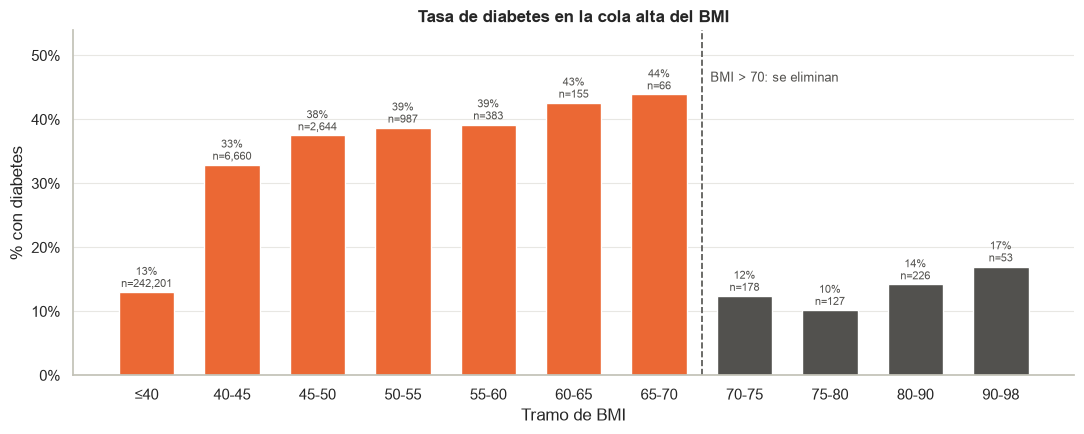

Frecuencia de cada valor de BMI > 70:
{71: 49, 72: 14, 73: 47, 74: 16, 75: 52, 76: 3, 77: 55, 78: 1, 79: 66, 80: 2, 81: 49, 82: 37, 83: 2, 84: 44, 85: 1, 86: 1, 87: 61, 88: 2, 89: 28, 90: 1, 91: 1, 92: 32, 95: 12, 96: 1, 98: 7}


In [46]:
# Tasa de diabetes en la cola alta del BMI: si los valores extremos son reales,
# la tasa debería seguir subiendo con el BMI (como ocurre de 25 a 40)
bins_bmi = [12, 40, 45, 50, 55, 60, 65, 70, 75, 80, 90, 98]
tramos_bmi = pd.cut(df["BMI"], bins=bins_bmi, include_lowest=True)
cola_bmi = df.groupby(tramos_bmi, observed=True)[TARGET].agg(registros="size", tasa_diabetes="mean")
cola_bmi["tasa_diabetes"] = (cola_bmi["tasa_diabetes"] * 100).round(1)
display(cola_bmi)

# Gráfica de la tasa de diabetes por tramo de BMI, marcando el umbral de corte
fig, ax = plt.subplots(figsize=(11, 4.5))
etiquetas_tramos = [f"{int(i.left)}-{int(i.right)}" if i.left > 12 else "≤40" for i in cola_bmi.index]
colores = [NARANJA if i.left < 70 else GRIS for i in cola_bmi.index]
ax.bar(etiquetas_tramos, cola_bmi["tasa_diabetes"], color=colores, width=0.65)
for x, (v, n) in enumerate(zip(cola_bmi["tasa_diabetes"], cola_bmi["registros"])):
    ax.text(x, v + 0.8, f"{v:.0f}%\nn={n:,}", ha="center", color=GRIS, fontsize=8)
ax.axvline(6.5, color=GRIS, ls="--", lw=1.2)
ax.text(6.6, cola_bmi["tasa_diabetes"].max() + 2, "BMI > 70: se eliminan", color=GRIS, fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, cola_bmi["tasa_diabetes"].max() + 10)
ax.set_xlabel("Tramo de BMI")
ax.set_ylabel("% con diabetes")
ax.set_title("Tasa de diabetes en la cola alta del BMI")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# Valores de BMI por encima de 70: llama la atención que se acumulen en ciertos números
print("Frecuencia de cada valor de BMI > 70:")
print(df.loc[df["BMI"] > 70, "BMI"].value_counts().sort_index().to_dict())

**Decisión 3. BMI: se eliminan los registros con BMI > 70 (≈ 0.2 % de los datos).**
- Entre 40 y 70, la tasa de diabetes **sigue subiendo** (33 % → 44 %), igual que en el resto del rango. Son personas con obesidad severa real y, además, son el grupo **más informativo** para el modelo. **No se tocan**, aunque la regla IQR las marque como outliers (cualquier BMI > 41.5).
- Por encima de 70 la relación **se rompe**: la tasa cae a 10–17 %, el nivel de la población general. Además, los valores se acumulan en números específicos (73, 75, 77, 79, 81, 84, 87…), un patrón típico de **errores de captura o de conversión de unidades** en el peso o la estatura autorreportados con los que BRFSS calcula el BMI. Un BMI > 70 es clínicamente excepcional y no es creíble que aparezca en cientos de encuestados.
- **¿Por qué eliminar y no recortar (*capping*) a 70?** Si el valor es un error, el BMI real es desconocido. Recortarlo a 70 le asignaría a esas personas obesidad extrema, lo cual contradice su tasa de diabetes observada e introduciría ruido. Como son pocos registros (≈ 580), eliminarlos es la opción más limpia.
- El umbral de 70 es **fijo y de dominio**, no un percentil calculado sobre los datos, así que no genera fuga de información y se puede aplicar igual en producción.
- Los valores bajos (BMI 12–14, 68 registros) son extremos pero fisiológicamente posibles (desnutrición severa) y se conservan.

**Decisión 4. `MentHlth` y `PhysHlth`: se conservan sin cambios.**
- La regla IQR marca como outliers 14–16 % de los registros, pero eso se debe a que la mayoría responde 0 días (el IQR es muy estrecho), no a que los valores sean erróneos.
- Todos los valores están dentro del dominio válido (0–30 días). El pico en 30 corresponde a personas con mala salud **crónica**, información clínicamente relevante.
- No se transforman: un baseline de regresión logística con escalado puede usarlas tal cual. Si en el futuro hiciera falta, se podrían discretizar (0, 1–13, 14–30 días).

### 3.4 Tipos de datos

Todas las columnas vienen como `int64`. No hay tipos "incorrectos" en el sentido de números guardados como texto, pero sí **tipos ineficientes** y **semánticamente imprecisos**.

In [47]:
# Tipos actuales y memoria utilizada
print("Tipos actuales:", df.dtypes.value_counts().to_dict())
print(f"Memoria con int64: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# Todas las variables caben en int8 (rango -128 a 127): la mayor es BMI, con máximo 98
print(f"Valor máximo en todo el dataset: {df.max().max()}")
print(f"Memoria con int8: {df.astype('int8').memory_usage(deep=True).sum() / 1e6:.1f} MB")

Tipos actuales: {dtype('int64'): 22}
Memoria con int64: 44.6 MB
Valor máximo en todo el dataset: 98
Memoria con int8: 5.6 MB


**Decisión 5. Tipos: convertir todas las columnas a `int8` y mantener la codificación numérica.**
- Todos los valores son enteros entre 0 y 98, así que `int8` los representa sin pérdida y **reduce la memoria 8 veces** (de ~45 MB a ~6 MB). Esto acelera el entrenamiento y abarata el almacenamiento de versiones del dataset.
- **Binarias:** se mantienen como 0/1 enteros, que es lo que esperan los modelos de scikit-learn.
- **Ordinales** (`GenHlth`, `Age`, `Education`, `Income`): se mantienen como códigos numéricos (*ordinal encoding*) porque el orden tiene significado (por ejemplo, la tasa de diabetes crece casi monótonamente con `Age` y `GenHlth`, como se vio en el EDA). Convertirlas a `category` obligaría a aplicar *one-hot encoding* y a perder ese orden, lo cual no es necesario para un modelo base.
- **`BMI`** se queda como entero porque el dataset ya viene redondeado; convertirlo a `float` no agrega información.

### 3.5 Función de limpieza reproducible

Todas las decisiones anteriores se concentran en una sola función. Así la limpieza es **reproducible**, se puede probar y se puede reutilizar sin cambios en el reentrenamiento o en el servicio de inferencia.

In [48]:
# Parámetros de limpieza (se registrarán en MLflow en el Paso 6)
PARAMS_LIMPIEZA = {
    "eliminar_duplicados": False,
    "bmi_max_plausible": 70,
    "tipo_datos": "int8",
}

def limpiar_datos(data, params=PARAMS_LIMPIEZA):
    # Trabaja sobre una copia para no modificar el DataFrame original
    data = data.copy()

    # 1. Validación de esquema: detiene el proceso si hay nulos o valores fuera de dominio
    assert data.isna().sum().sum() == 0, "Hay valores faltantes"
    for col, (lo, hi) in ESQUEMA.items():
        assert data[col].between(lo, hi).all(), f"{col} tiene valores fuera de dominio"

    # 2. Duplicados (se conservan por defecto, ver Decisión 2)
    if params["eliminar_duplicados"]:
        data = data.drop_duplicates()

    # 3. Outliers: elimina registros con BMI no plausible
    data = data[data["BMI"] <= params["bmi_max_plausible"]]

    # 4. Tipos: conversión a un tipo compacto
    data = data.astype(params["tipo_datos"])

    return data.reset_index(drop=True)

df_limpio = limpiar_datos(df)

In [49]:
# Verificaciones del resultado de la limpieza
assert df_limpio["BMI"].max() <= PARAMS_LIMPIEZA["bmi_max_plausible"]
assert (df_limpio.dtypes == "int8").all()
assert df_limpio.isna().sum().sum() == 0

# Comparación antes vs. después
resumen_limpieza = pd.DataFrame({
    "original": {
        "registros": len(df),
        "BMI máximo": df["BMI"].max(),
        "tasa de diabetes (%)": round(df[TARGET].mean() * 100, 2),
        "memoria (MB)": round(df.memory_usage(deep=True).sum() / 1e6, 1),
    },
    "limpio": {
        "registros": len(df_limpio),
        "BMI máximo": df_limpio["BMI"].max(),
        "tasa de diabetes (%)": round(df_limpio[TARGET].mean() * 100, 2),
        "memoria (MB)": round(df_limpio.memory_usage(deep=True).sum() / 1e6, 1),
    },
}, dtype=object)
print(f"Registros eliminados: {len(df) - len(df_limpio):,} ({(len(df) - len(df_limpio)) / len(df):.2%})")
resumen_limpieza

Registros eliminados: 584 (0.23%)


,original,limpio
registros,253680.0,253096.0
BMI máximo,98.0,70.0
tasa de diabetes (%),13.93,13.94
memoria (MB),44.6,5.6


### 3.6 Registro de decisiones

| # | Problema | Evidencia | Decisión | Impacto |
|---|---|---|---|---|
| 1 | Valores faltantes | 0 `NaN` y 0 valores fuera del dominio documentado | No se imputa; el esquema se conserva como validación | Ninguno |
| 2 | Duplicados (~24,200 filas, 9.5 %) | Sin ID de persona; variables discretas; se concentran en el perfil sano más común (~1 % con diabetes) | **Se conservan** | Evita sesgar la prevalencia de 13.9 % a 15.3 % |
| 3 | BMI > 70 (≈ 580 filas) | La tasa de diabetes deja de crecer y cae al nivel de la población general; valores acumulados en números específicos | **Se eliminan** (umbral fijo de dominio) | −0.2 % de registros |
| 3b | BMI 41.5–70 (outliers IQR) | La tasa de diabetes sigue creciendo de forma coherente | Se conservan | Mantiene al grupo de mayor riesgo |
| 4 | `MentHlth` / `PhysHlth` (outliers IQR) | Valores dentro del dominio 0–30; distribución concentrada en 0 | Se conservan sin transformar | Ninguno |
| 5 | Tipos `int64` | Todos los valores son enteros entre 0 y 98 | Conversión a `int8`; ordinales con codificación numérica | Memoria ÷ 8 |

**Para los siguientes pasos:** el modelo se entrena con `df_limpio`. El escalado de variables y cualquier otra transformación que aprenda de los datos se ajusta **solo con el conjunto de entrenamiento** dentro de un `Pipeline` de scikit-learn (Paso 4).

## Paso 4: Entrena un modelo base:

Selecciona un modelo sencillo (baseline) apropiado para el problema.
Divide los datos en entrenamiento y prueba, y entrénalo.

### 4.1 Selección del modelo base

**Modelo elegido: Regresión Logística** (`LogisticRegression` de scikit-learn) dentro de un `Pipeline` con `StandardScaler`.

| Criterio | Por qué la regresión logística es apropiada |
|---|---|
| **Tipo de problema** | Clasificación binaria (`Diabetes_binary` = 0/1). Es el modelo lineal estándar para este tipo de problema. |
| **Sencillez** | Pocos hiperparámetros, entrena en segundos con ~250 mil registros y es fácil de reproducir. Es justo lo que se espera de un *baseline*: un punto de referencia para comparar modelos más complejos. |
| **Interpretabilidad** | Cada coeficiente indica cuánto aumenta o disminuye el riesgo de diabetes cada variable. En un contexto de salud es importante poder explicar las predicciones. |
| **Probabilidades** | Entrega una probabilidad de diabetes, no solo una clase. Esto permite ajustar el umbral de decisión según el costo de los errores (Paso 5). |
| **Coherente con el EDA** | El EDA mostró relaciones mayormente **monótonas** con el objetivo (más BMI, edad o peor salud → más diabetes) y sin multicolinealidad fuerte (\|r\| ≤ 0.52). Un modelo lineal puede capturar bien esas relaciones. |

**Decisiones de configuración:**
- **`class_weight="balanced"`**: con un desbalance de ~86/14, un modelo sin ajuste tiende a predecir casi siempre "sin diabetes". Con esta opción, los errores en la clase minoritaria pesan ~6 veces más, lo que mejora la detección de personas con diabetes.
- **`StandardScaler`**: `BMI` (12–70) y los conteos de días (0–30) tienen escalas muy distintas a las variables binarias (0–1). La regularización de la regresión logística es sensible a la escala, así que estandarizamos. Al ir dentro del `Pipeline`, el escalador **se ajusta solo con entrenamiento**, lo que evita la fuga de información.
- **Codificación de variables:** se usa la codificación numérica definida en el Paso 3 (las ordinales mantienen su orden).

Como **piso de referencia** entrenamos además un `DummyClassifier`, que predice al azar respetando la proporción de clases. Si la regresión logística no lo supera claramente, el modelo no está aprendiendo nada útil.

### 4.2 Partición en entrenamiento, validación y prueba

Usamos **tres particiones estratificadas** (70 / 15 / 15), cada una con un rol distinto:

| Partición | % | Uso |
|---|---|---|
| **Entrenamiento** | 70 % | Ajustar el modelo (escalador y coeficientes). |
| **Validación** | 15 % | Tomar decisiones sobre el modelo: elegir el hiperparámetro de regularización `C`, revisar el sobreajuste y, en el Paso 5, elegir el umbral de decisión. |
| **Prueba** | 15 % | Se usa **una sola vez**, al final, para estimar el desempeño real en datos nunca vistos. No se usa para ninguna decisión, porque entonces dejaría de ser una estimación honesta. |

- **Estratificación (`stratify`)**: garantiza que las tres particiones tengan la misma proporción de diabetes (~13.9 %). Sin ella, con una clase minoritaria, cada partición podría quedar con una proporción distinta.
- **Semilla fija (`random_state=42`)**: la partición es reproducible, requisito básico para poder comparar experimentos en MLflow.

In [50]:
from sklearn.model_selection import train_test_split

# Parámetros de la partición (se registrarán en MLflow en el Paso 6)
SEMILLA = 42
PARAMS_PARTICION = {"test_size": 0.15, "val_size": 0.15, "random_state": SEMILLA, "estratificado": True}

# Separa predictoras (X) y variable objetivo (y) del dataset limpio
X_total = df_limpio.drop(columns=TARGET)
y_total = df_limpio[TARGET]

# Primera división: separa el 15 % de prueba
X_temp, X_test, y_temp, y_test = train_test_split(
    X_total, y_total, test_size=PARAMS_PARTICION["test_size"],
    stratify=y_total, random_state=SEMILLA)

# Segunda división: del 85 % restante, separa validación (15 % del total)
val_relativo = PARAMS_PARTICION["val_size"] / (1 - PARAMS_PARTICION["test_size"])
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_relativo, stratify=y_temp, random_state=SEMILLA)

# Tamaño y proporción de diabetes en cada partición
resumen_particion = pd.DataFrame({
    "registros": [len(y_train), len(y_val), len(y_test)],
    "% del total": [len(y_train) / len(y_total) * 100, len(y_val) / len(y_total) * 100, len(y_test) / len(y_total) * 100],
    "% con diabetes": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["entrenamiento", "validación", "prueba"]).round(2)
resumen_particion

,registros,% del total,% con diabetes
entrenamiento,177166,70.0,13.93
validación,37965,15.0,13.94
prueba,37965,15.0,13.94


### 4.3 Entrenamiento y selección del hiperparámetro `C` con validación

`C` controla la **regularización** (qué tanto se penalizan los coeficientes grandes): valores pequeños dan un modelo más simple, valores grandes uno más flexible. Probamos unos cuantos valores, entrenando siempre con **entrenamiento** y comparando en **validación**.

Para comparar usamos **ROC-AUC**: mide qué tan bien el modelo ordena a las personas por riesgo (1.0 = perfecto, 0.5 = azar). No depende del umbral de decisión y no se ve inflada por el desbalance de clases, a diferencia de *accuracy*.

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score
import time

# Construye el pipeline: escalado + regresión logística
def crear_modelo(C):
    return Pipeline([
        ("escalador", StandardScaler()),
        ("modelo", LogisticRegression(C=C, class_weight="balanced", max_iter=1000, random_state=SEMILLA)),
    ])

# Prueba distintos valores de C: entrena con train y evalúa en validación
resultados_C = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    modelo_c = crear_modelo(C).fit(X_train, y_train)
    resultados_C.append({
        "C": C,
        "ROC-AUC entrenamiento": roc_auc_score(y_train, modelo_c.predict_proba(X_train)[:, 1]),
        "ROC-AUC validación": roc_auc_score(y_val, modelo_c.predict_proba(X_val)[:, 1]),
    })
resultados_C = pd.DataFrame(resultados_C).set_index("C").round(4)
resultados_C

,ROC-AUC entrenamiento,ROC-AUC validación
C,,
0.001,0.8247,0.8236
0.010,0.8247,0.8234
0.100,0.8247,0.8234
1.000,0.8247,0.8234
10.000,0.8247,0.8234


**Resultado:** la ROC-AUC en validación es prácticamente la misma para todos los valores de `C` (0.8234–0.8236). Con ~177 mil registros y solo 21 variables, el modelo tiene muchos más datos que parámetros, así que la regularización casi no influye. Elegimos el `C` con mejor ROC-AUC en validación (0.001), que además es el de **mayor regularización**: ante un empate práctico conviene el modelo más simple.

In [52]:
# Elige el C con mejor ROC-AUC en validación
MEJOR_C = resultados_C["ROC-AUC validación"].idxmax()

# Parámetros del modelo final (se registrarán en MLflow en el Paso 6)
PARAMS_MODELO = {
    "modelo": "LogisticRegression",
    "C": MEJOR_C,
    "class_weight": "balanced",
    "max_iter": 1000,
    "escalado": "StandardScaler",
}

# Entrena el modelo base final con el conjunto de entrenamiento
inicio = time.time()
modelo_base = crear_modelo(MEJOR_C).fit(X_train, y_train)
tiempo_entrenamiento = time.time() - inicio

# Modelo de referencia que predice al azar respetando la proporción de clases
modelo_dummy = DummyClassifier(strategy="stratified", random_state=SEMILLA).fit(X_train, y_train)

print(f"C seleccionado: {MEJOR_C}")
print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.2f} s")
print(f"Iteraciones hasta converger: {modelo_base.named_steps['modelo'].n_iter_[0]}")

C seleccionado: 0.001
Tiempo de entrenamiento: 0.07 s
Iteraciones hasta converger: 11


### 4.4 Verificación del entrenamiento

Antes de la evaluación formal (Paso 5) revisamos que el modelo **aprendió algo útil** (supera al azar) y que **no está sobreajustado** (desempeño similar en entrenamiento y validación). El conjunto de prueba **todavía no se usa**.

In [53]:
# ROC-AUC del modelo base y del modelo de referencia en entrenamiento y validación
verificacion = pd.DataFrame({
    "entrenamiento": [roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]) for m in (modelo_dummy, modelo_base)],
    "validación": [roc_auc_score(y_val, m.predict_proba(X_val)[:, 1]) for m in (modelo_dummy, modelo_base)],
}, index=["DummyClassifier (azar)", "Regresión logística"]).round(4)
verificacion["diferencia"] = (verificacion["entrenamiento"] - verificacion["validación"]).round(4)
verificacion

,entrenamiento,validación,diferencia
DummyClassifier (azar),0.4994,0.5003,-0.0009
Regresión logística,0.8247,0.8236,0.0011


**Interpretación:**
- **El modelo aprende patrones reales:** su ROC-AUC en validación es **≈ 0.82**, contra **≈ 0.50** del modelo al azar. Dicho de forma práctica: si se toma al azar una persona con diabetes y otra sin ella, el modelo le asigna mayor riesgo a la que sí tiene diabetes en ~82 % de los casos.
- **No hay sobreajuste:** la diferencia entre entrenamiento y validación es de apenas ~0.001. Es lo esperado en un modelo lineal entrenado con muchos datos.
- La contraparte es que el modelo está **limitado por su simplicidad** (sesgo): no captura interacciones ni relaciones no lineales (por ejemplo, la tasa de diabetes que baja después de los 80 años). Esto deja margen para que modelos más flexibles (árboles, *gradient boosting*) lo mejoren en iteraciones futuras, y esta ROC-AUC queda como **la referencia a superar**.
- La evaluación completa, con métricas por clase, umbral de decisión y el conjunto de prueba, se hace en el Paso 5.

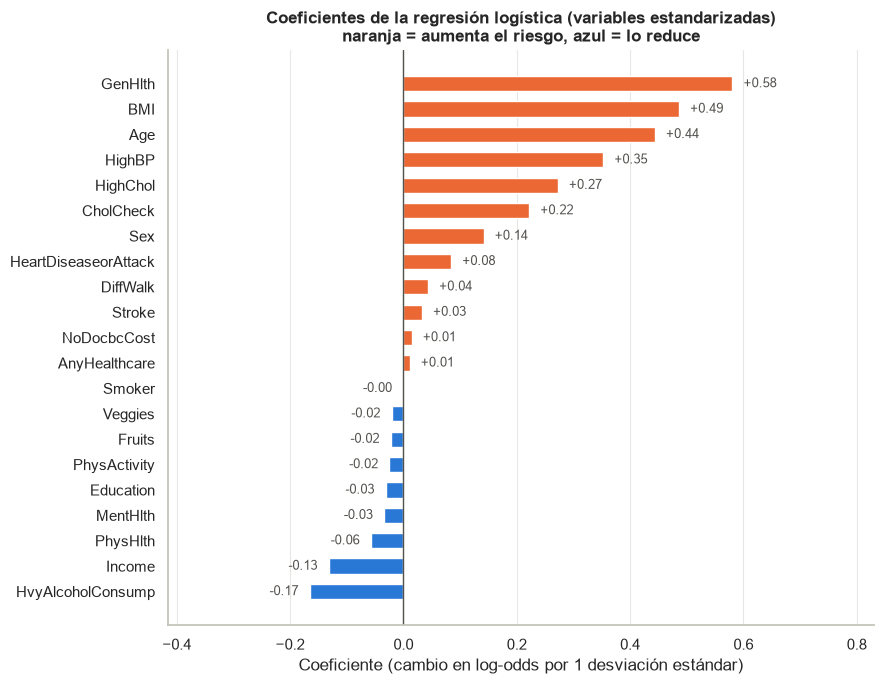

In [54]:
# Coeficientes del modelo: como las variables están estandarizadas, su magnitud es comparable
coeficientes = pd.Series(modelo_base.named_steps["modelo"].coef_[0], index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
colores = [NARANJA if v > 0 else AZUL for v in coeficientes.values]
ax.barh(coeficientes.index, coeficientes.values, color=colores, height=0.6)
for i, v in enumerate(coeficientes.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=GRIS)
ax.axvline(0, color=GRIS, lw=1)
ax.set_xlim(coeficientes.min() - 0.25, coeficientes.max() + 0.25)
ax.set_title("Coeficientes de la regresión logística (variables estandarizadas)\nnaranja = aumenta el riesgo, azul = lo reduce")
ax.set_xlabel("Coeficiente (cambio en log-odds por 1 desviación estándar)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Interpretación de los coeficientes:**
- Las variables con más peso coinciden con el EDA: **`GenHlth`, `BMI`, `Age`, `HighBP` y `HighChol`** son los principales factores que aumentan el riesgo estimado, mientras que **`Income`** y `HvyAlcoholConsump` lo reducen.
- Algunas variables pesan menos de lo que el EDA sugería, porque cada coeficiente mide el efecto **manteniendo constantes las demás variables**. Por ejemplo, `DiffWalk`, `Stroke` y `HeartDiseaseorAttack` tenían riesgos relativos altos en el EDA, pero aquí aportan poco porque buena parte de su información ya está en `GenHlth` y `Age`, con las que están correlacionadas. Por la misma razón, `PhysHlth` aparece incluso con signo negativo (su correlación con `GenHlth` es 0.52).
- `CholCheck` (+0.22) y `HvyAlcoholConsump` (−0.17) **no deben leerse como causas**: es más probable que reflejen que las personas con diagnóstico se revisan más el colesterol y que quienes tienen diabetes reducen el consumo de alcohol (causalidad inversa o confusión).
- En general, los coeficientes de este modelo describen **asociaciones útiles para predecir, no efectos causales**.

## Paso 5: Evalúa el modelo:

Calcula al menos una métrica de desempeño coherente con el tipo de problema.
Interpreta el resultado de manera detallada.

### 5.1 Elección de métricas

El problema es de **clasificación binaria con clases desbalanceadas** (~14 % con diabetes). En este contexto, *accuracy* es engañosa: un modelo que diga siempre "sin diabetes" acertaría el 86 % de las veces sin detectar a nadie. Por eso usamos métricas que se fijan en la clase positiva:

| Métrica | Qué responde | Por qué es relevante aquí |
|---|---|---|
| **ROC-AUC** (principal) | ¿Qué tan bien ordena el modelo a las personas por riesgo? | No depende del umbral ni del desbalance. Es la métrica para comparar modelos. |
| **PR-AUC** (*average precision*) | ¿Qué tan bien encuentra a los positivos sin generar demasiadas falsas alarmas? | Es más exigente con el desbalance. Su referencia no es 0.5, sino la prevalencia (~0.14). |
| **Recall** (sensibilidad) | De las personas con diabetes, ¿a cuántas detecta? | Es la métrica clave para un **tamizaje**: un caso no detectado (falso negativo) es el error más costoso. |
| **Precisión** | De las personas que el modelo marca como riesgo, ¿cuántas realmente tienen diabetes? | Mide el costo en falsas alarmas (pruebas de laboratorio innecesarias). |
| **F1** | Balance entre precisión y recall. | Resume ambas en un número. |
| **Especificidad** | De las personas sanas, ¿a cuántas descarta correctamente? | Complementa al recall. |

ROC-AUC y PR-AUC evalúan las **probabilidades**. Recall, precisión, F1 y especificidad evalúan las **decisiones**, que dependen de un **umbral**: si la probabilidad es ≥ umbral, se predice "diabetes".

### 5.2 Selección del umbral de decisión (con validación)

El umbral por defecto (0.5) no tiene por qué ser el mejor; debe elegirse según **el uso del modelo**. Aquí el modelo funcionaría como **herramienta de tamizaje** para decidir a quién recomendar una prueba de glucosa:
- Un **falso negativo** es una persona con diabetes que no recibe seguimiento y cuya enfermedad avanza sin control: **costo alto**.
- Un **falso positivo** es una persona sana a la que se le hace una prueba de laboratorio sencilla y barata: **costo bajo**.

**Criterio:** elegir el umbral **más alto que mantenga un recall de al menos 80 %** (detectar 4 de cada 5 casos), para no generar más falsas alarmas de las necesarias. El umbral se elige con el conjunto de **validación**; el de prueba sigue sin usarse.

In [55]:
from sklearn.metrics import (precision_recall_curve, recall_score, precision_score, f1_score,
                             accuracy_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve)

# Probabilidades de diabetes en validación
prob_val = modelo_base.predict_proba(X_val)[:, 1]

# Precisión y recall para todos los umbrales posibles
precision_val, recall_val, umbrales = precision_recall_curve(y_val, prob_val)
precision_val, recall_val = precision_val[:-1], recall_val[:-1]
f1_val = 2 * precision_val * recall_val / (precision_val + recall_val)

# Umbral elegido: el más alto que mantiene recall >= 80 %
RECALL_MINIMO = 0.80
UMBRAL = umbrales[recall_val >= RECALL_MINIMO].max()

# Comparación de tres umbrales candidatos en validación
def metricas_umbral(y_real, prob, umbral):
    y_pred = (prob >= umbral).astype(int)
    return {"recall": recall_score(y_real, y_pred), "precisión": precision_score(y_real, y_pred),
            "F1": f1_score(y_real, y_pred), "accuracy": accuracy_score(y_real, y_pred),
            "% marcados como riesgo": y_pred.mean() * 100}

candidatos = {
    "0.50 (por defecto)": 0.5,
    f"{umbrales[np.argmax(f1_val)]:.2f} (máximo F1)": umbrales[np.argmax(f1_val)],
    f"{UMBRAL:.2f} (recall ≥ 80 %, elegido)": UMBRAL,
}
comparacion_umbrales = pd.DataFrame({k: metricas_umbral(y_val, prob_val, u) for k, u in candidatos.items()}).T.round(3)
comparacion_umbrales.index.name = "umbral"
comparacion_umbrales

,recall,precisión,F1,accuracy,% marcados como riesgo
umbral,,,,,
0.50 (por defecto),0.767,0.313,0.445,0.733,34.124
0.61 (máximo F1),0.643,0.363,0.464,0.793,24.712
"0.47 (recall ≥ 80 %, elegido)",0.800,0.298,0.435,0.710,37.363


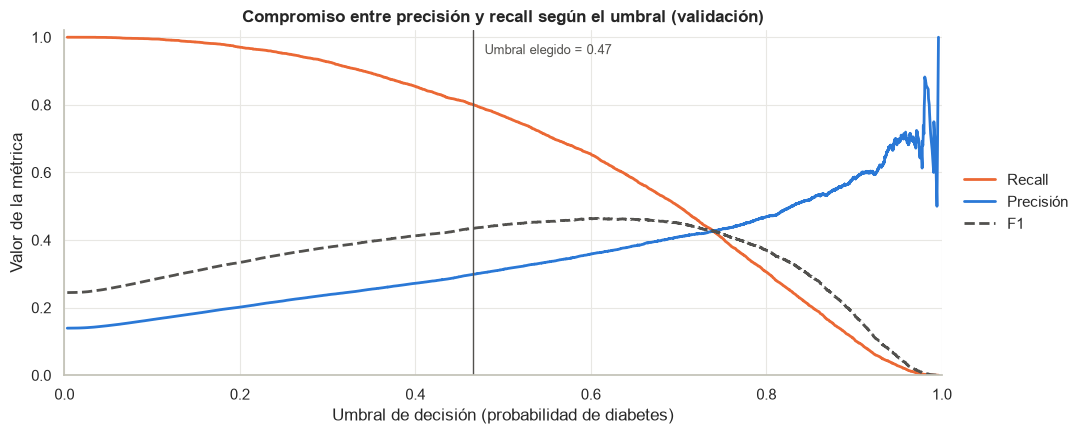

In [56]:
# Cómo cambian precisión, recall y F1 al mover el umbral
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(umbrales, recall_val, color=NARANJA, lw=2, label="Recall")
ax.plot(umbrales, precision_val, color=AZUL, lw=2, label="Precisión")
ax.plot(umbrales, f1_val, color=GRIS, lw=2, ls="--", label="F1")
# Marca el umbral elegido
ax.axvline(UMBRAL, color=GRIS, lw=1)
ax.annotate(f"Umbral elegido = {UMBRAL:.2f}", (UMBRAL, 0.95), xytext=(8, 0),
            textcoords="offset points", fontsize=9, color=GRIS)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Umbral de decisión (probabilidad de diabetes)")
ax.set_ylabel("Valor de la métrica")
ax.set_title("Compromiso entre precisión y recall según el umbral (validación)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

**Decisión del umbral: 0.47.**
- Con **0.50** el modelo detecta 76.7 % de los casos. Con el umbral que **maximiza F1 (0.61)** la detección baja a 64.3 %: más de un tercio de las personas con diabetes no se detectaría. F1 le da el mismo peso a precisión y recall, lo cual no refleja los costos reales de este problema.
- Con **0.47** se alcanza la meta de **80 % de recall**, a cambio de bajar la precisión de 31.3 % a 29.8 % y de marcar como riesgo a 37 % de la población en lugar de 34 %. Es un costo pequeño (unas cuantas pruebas de glucosa adicionales) a cambio de detectar más casos.
- La gráfica muestra el compromiso: al bajar el umbral, el recall sube y la precisión baja. No existe un umbral que maximice ambas, así que la elección depende del uso que se le dará al modelo.
- Si el modelo se usara en otro contexto (por ejemplo, con recursos de seguimiento muy limitados), bastaría con cambiar `RECALL_MINIMO` y volver a ejecutar; **no hay que reentrenar**.

### 5.3 Evaluación final en el conjunto de prueba

Con el modelo y el umbral ya fijados, evaluamos **una sola vez** en el conjunto de prueba. Este resultado es la estimación más honesta del desempeño que tendría el modelo con personas nuevas.

In [57]:
# Probabilidades y predicciones en prueba (modelo base y modelo de referencia)
prob_test = modelo_base.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= UMBRAL).astype(int)
prob_dummy = modelo_dummy.predict_proba(X_test)[:, 1]
pred_dummy = modelo_dummy.predict(X_test)

# Calcula todas las métricas de un modelo
def calcular_metricas(y_real, prob, pred):
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
    return {
        "roc_auc": roc_auc_score(y_real, prob),
        "pr_auc": average_precision_score(y_real, prob),
        "recall": recall_score(y_real, pred),
        "precision": precision_score(y_real, pred),
        "f1": f1_score(y_real, pred),
        "especificidad": tn / (tn + fp),
        "accuracy": accuracy_score(y_real, pred),
    }

# Métricas finales del modelo base (se registrarán en MLflow en el Paso 6)
METRICAS_PRUEBA = calcular_metricas(y_test, prob_test, pred_test)

resultados_prueba = pd.DataFrame({
    "DummyClassifier (azar)": calcular_metricas(y_test, prob_dummy, pred_dummy),
    "Regresión logística": METRICAS_PRUEBA,
}).round(3)
display(resultados_prueba)

# Generalización: compara las métricas de ranking en validación y prueba
print(f"ROC-AUC  validación: {roc_auc_score(y_val, prob_val):.3f} | prueba: {METRICAS_PRUEBA['roc_auc']:.3f}")
print(f"PR-AUC   validación: {average_precision_score(y_val, prob_val):.3f} | prueba: {METRICAS_PRUEBA['pr_auc']:.3f}")

,DummyClassifier (azar),Regresión logística
roc_auc,0.503,0.823
pr_auc,0.140,0.409
recall,0.143,0.796
precision,0.144,0.299
f1,0.143,0.435
especificidad,0.862,0.698
accuracy,0.762,0.712


ROC-AUC  validación: 0.824 | prueba: 0.823
PR-AUC   validación: 0.413 | prueba: 0.409


                          precision    recall  f1-score   support

        Sin diabetes (0)      0.955     0.698     0.806     32674
Prediabetes/diabetes (1)      0.299     0.796     0.435      5291

                accuracy                          0.712     37965
               macro avg      0.627     0.747     0.621     37965
            weighted avg      0.863     0.712     0.755     37965



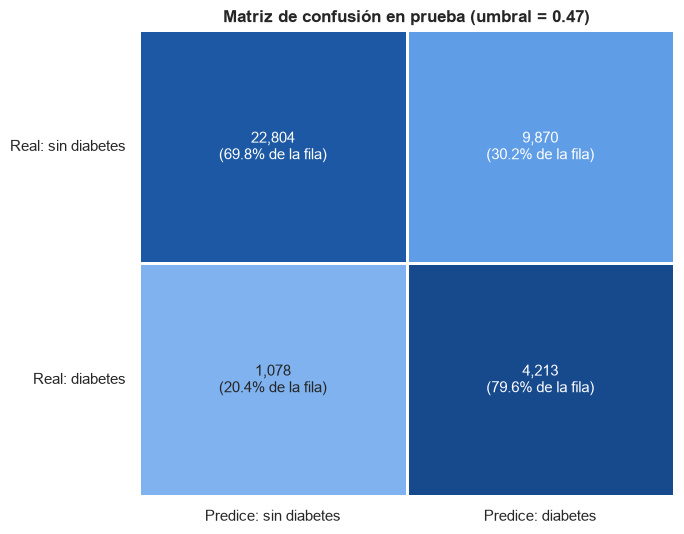

In [58]:
# Reporte por clase con el umbral elegido
print(classification_report(y_test, pred_test, target_names=["Sin diabetes (0)", "Prediabetes/diabetes (1)"], digits=3))

# Matriz de confusión con conteos y porcentaje por fila (clase real)
matriz = confusion_matrix(y_test, pred_test)
pct_fila = matriz / matriz.sum(axis=1, keepdims=True) * 100
etiquetas_celda = np.array([[f"{matriz[i, j]:,}\n({pct_fila[i, j]:.1f}% de la fila)" for j in range(2)] for i in range(2)])

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(pct_fila, annot=etiquetas_celda, fmt="", cmap=CMAP_SECUENCIAL, vmin=0, vmax=100,
            linewidths=2, linecolor="white", cbar=False, annot_kws={"size": 11}, ax=ax)
ax.set_xticklabels(["Predice: sin diabetes", "Predice: diabetes"])
ax.set_yticklabels(["Real: sin diabetes", "Real: diabetes"], rotation=0)
ax.set_title(f"Matriz de confusión en prueba (umbral = {UMBRAL:.2f})")
plt.tight_layout()
plt.show()

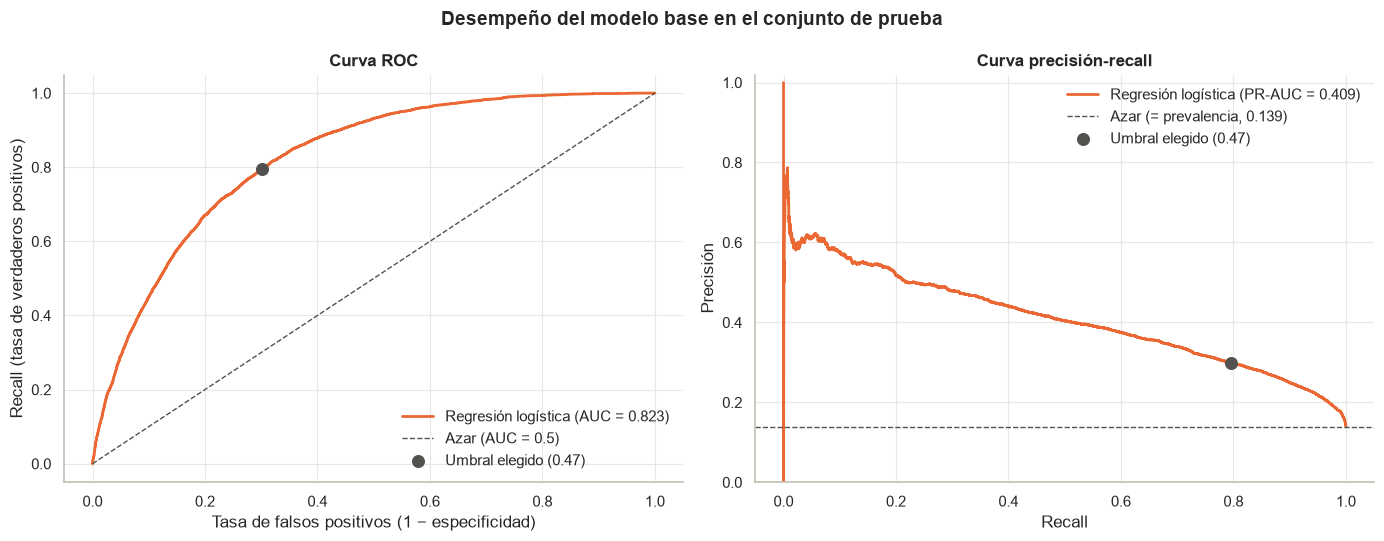

In [59]:
# Curvas ROC y precisión-recall en prueba
fpr, tpr, _ = roc_curve(y_test, prob_test)
prec_curva, rec_curva, _ = precision_recall_curve(y_test, prob_test)
prevalencia_test = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Curva ROC: la diagonal representa un modelo al azar
axes[0].plot(fpr, tpr, color=NARANJA, lw=2, label=f"Regresión logística (AUC = {METRICAS_PRUEBA['roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRIS, lw=1, ls="--", label="Azar (AUC = 0.5)")
axes[0].scatter(1 - METRICAS_PRUEBA["especificidad"], METRICAS_PRUEBA["recall"], color=GRIS, s=70, zorder=3,
                label=f"Umbral elegido ({UMBRAL:.2f})")
axes[0].set_xlabel("Tasa de falsos positivos (1 − especificidad)")
axes[0].set_ylabel("Recall (tasa de verdaderos positivos)")
axes[0].set_title("Curva ROC")
axes[0].legend(frameon=False, loc="lower right")

# Curva precisión-recall: la línea horizontal es la prevalencia (modelo al azar)
axes[1].plot(rec_curva, prec_curva, color=NARANJA, lw=2, label=f"Regresión logística (PR-AUC = {METRICAS_PRUEBA['pr_auc']:.3f})")
axes[1].axhline(prevalencia_test, color=GRIS, lw=1, ls="--", label=f"Azar (= prevalencia, {prevalencia_test:.3f})")
axes[1].scatter(METRICAS_PRUEBA["recall"], METRICAS_PRUEBA["precision"], color=GRIS, s=70, zorder=3,
                label=f"Umbral elegido ({UMBRAL:.2f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisión")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Curva precisión-recall")
axes[1].legend(frameon=False, loc="upper right")

plt.suptitle("Desempeño del modelo base en el conjunto de prueba", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

### 5.4 Interpretación detallada de los resultados

**1. Capacidad de discriminación: ROC-AUC = 0.823 (métrica principal)**
- Si se elige al azar una persona con diabetes y otra sin diabetes, el modelo le asigna mayor probabilidad de diabetes a la que sí la tiene en **82 % de los casos**. Un modelo al azar lo haría en 50 %.
- En la literatura de modelos de riesgo clínico, un AUC entre 0.80 y 0.90 se considera **buena** discriminación. Es un resultado sólido para un modelo lineal entrenado solo con respuestas de una encuesta, **sin datos de laboratorio** (glucosa o hemoglobina glucosilada).

**2. Desempeño frente a la clase minoritaria: PR-AUC = 0.409**
- A diferencia de ROC-AUC, la referencia de PR-AUC es la prevalencia: un modelo al azar obtiene **0.139**. El modelo base obtiene casi **3 veces** ese valor.
- Que no se acerque a 1 muestra la dificultad real del problema: con una clase minoritaria de 14 %, aun un modelo con buena capacidad de ordenamiento genera muchas falsas alarmas.

**3. Decisiones con el umbral elegido (0.47): qué pasaría con 1,000 personas**

Con las proporciones observadas en prueba, de cada 1,000 personas (≈ 139 con diabetes):

| Resultado | Personas | Significado |
|---|---|---|
| Verdaderos positivos | **111** | Personas con diabetes detectadas → reciben seguimiento |
| Falsos negativos | **28** | Personas con diabetes **no detectadas** → el error más costoso |
| Falsos positivos | **260** | Personas sanas enviadas a una prueba de glucosa innecesaria |
| Verdaderos negativos | **601** | Personas sanas descartadas correctamente |

- **Recall = 79.6 %:** el modelo detecta 4 de cada 5 personas con diabetes, como se buscaba al elegir el umbral.
- **Precisión = 29.9 %:** de las personas que marca como riesgo, ~3 de cada 10 tienen diabetes. Parece bajo, pero es **más del doble** de la prevalencia (13.9 %): enfocar las pruebas en este grupo es 2.1 veces más eficiente que hacerlas al azar.
- **Valor predictivo negativo = 95.5 %:** de las personas que el modelo descarta, solo 4.5 % tiene diabetes, frente a 13.9 % en la población general. Ser descartado por el modelo es una señal confiable de bajo riesgo.
- **Especificidad = 69.8 %:** el modelo descarta correctamente a 7 de cada 10 personas sanas. El 30 % restante son las falsas alarmas, el costo de priorizar el recall.

**4. Por qué *accuracy* no es una buena métrica aquí**

El modelo al azar (`DummyClassifier`) tiene **mayor accuracy (0.762) que la regresión logística (0.712)**, a pesar de que solo detecta 14 % de los casos de diabetes frente a 80 %. Esto confirma lo anticipado en el EDA: con clases desbalanceadas, *accuracy* premia predecir la clase mayoritaria y castiga al modelo que hace el trabajo útil.

**5. Generalización**
- ROC-AUC: validación **0.824** vs. prueba **0.823**. PR-AUC: **0.413** vs. **0.409**.
- Las métricas son prácticamente iguales en datos que el modelo nunca vio, y también iguales a las de entrenamiento (Paso 4). El modelo **generaliza bien** y la estimación de desempeño es confiable.

**6. Limitaciones y siguientes pasos**
- **Precisión baja:** es la principal debilidad. Modelos que capturen relaciones no lineales e interacciones (por ejemplo, la combinación de edad y salud general), como *gradient boosting*, podrían mejorar la precisión manteniendo el recall. Cualquier modelo nuevo deberá superar **ROC-AUC = 0.823** y **PR-AUC = 0.409** en las mismas particiones.
- **Datos autorreportados:** el modelo depende de respuestas de encuesta (peso, diagnósticos previos), con el error que eso conlleva. Por eso **no sustituye un diagnóstico clínico**: su uso adecuado es priorizar a quién hacerle una prueba de laboratorio.
- **Equidad:** `Sex`, `Income` y `Education` son atributos sensibles. Antes de usar el modelo en un entorno real habría que verificar que el recall sea similar entre grupos, para no dejar sin detectar a una población en particular.
- **Calibración:** como se entrenó con `class_weight="balanced"`, las probabilidades del modelo están infladas respecto al riesgo real. Sirven para **ordenar** y para decidir con el umbral elegido, pero no deben comunicarse como "su probabilidad de tener diabetes es X %" sin calibrarlas antes.

## Paso 6: Registra el experimento en MLFlow:

Usa MLFlow Tracking para registrar parámetros y métricas.
Solo si aplica, registra los artefactos del modelo base.

### 6.1 Qué se registra y por qué

Registramos el experimento completo en **MLflow Tracking**, de modo que cualquier persona pueda **reproducir** el modelo y **comparar** futuros modelos contra este baseline en las mismas condiciones.

| Elemento | Contenido | Para qué sirve |
|---|---|---|
| **Parámetros** | Limpieza (`PARAMS_LIMPIEZA`), partición (`PARAMS_PARTICION`), modelo (`PARAMS_MODELO`), umbral de decisión | Reproducir exactamente el mismo flujo |
| **Métricas** | ROC-AUC, PR-AUC, recall, precisión, F1, especificidad y accuracy en **prueba**; ROC-AUC en entrenamiento y validación; métricas del modelo al azar | Evaluar y comparar modelos; detectar sobreajuste |
| **Tags** | Etapa, familia del modelo, dataset, autor | Buscar y filtrar ejecuciones en la interfaz de MLflow |
| **Datasets** | Entrenamiento, validación y prueba (`mlflow.log_input`) | Trazabilidad: saber con qué datos se entrenó y evaluó el modelo |
| **Artefactos** | Gráficas (matriz de confusión, curvas ROC y PR, coeficientes) y tablas (selección de `C` y del umbral) | Documentar la evaluación junto con la ejecución |
| **Modelo** | `Pipeline` completo (escalador + regresión logística) con firma y ejemplo de entrada, registrado en el **Model Registry** | Reutilizarlo para inferencia y versionarlo |

**¿Aplica registrar el modelo?** Sí. Aunque sea un modelo sencillo, es la **referencia** contra la que se compararán los siguientes modelos y la primera versión candidata a producción. Se registra el `Pipeline` completo, no solo la regresión logística, para que el escalado viaje junto con el modelo y no pueda olvidarse al hacer inferencia.

### 6.2 Configuración de MLflow

Antes de ejecutar esta sección, el servidor de MLflow debe estar corriendo en una terminal, por ejemplo:

```bash
mlflow server --host 127.0.0.1 --port 5000
```

In [60]:
import mlflow
from mlflow.models import infer_signature

# Desactiva el registro automático: registramos todo de forma explícita
mlflow.autolog(disable=True)

# Servidor de tracking y nombre del experimento
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("diabetes-baseline-TC5061")

NOMBRE_MODELO_REGISTRADO = "diabetes-baseline-logreg"
print(f"Tracking URI: {mlflow.get_tracking_uri()}")

2026/10/01 20:18:12 INFO mlflow.tracking.fluent: Experiment with name 'diabetes-baseline-TC5061' does not exist. Creating a new experiment.


Tracking URI: http://127.0.0.1:5000


### 6.3 Registro del experimento

In [61]:
from sklearn.metrics import ConfusionMatrixDisplay
import warnings

# MLflow advierte que las columnas enteras no admiten valores faltantes; no aplica aquí
# porque el Paso 3 validó que no hay faltantes y todas las variables son enteras por definición
warnings.filterwarnings("ignore", message="Hint: Inferred schema contains integer column")

# Métricas adicionales: ROC-AUC en entrenamiento y validación, y métricas del modelo al azar
metricas_extra = {
    "train_roc_auc": roc_auc_score(y_train, modelo_base.predict_proba(X_train)[:, 1]),
    "val_roc_auc": roc_auc_score(y_val, prob_val),
    "val_pr_auc": average_precision_score(y_val, prob_val),
}
metricas_dummy = calcular_metricas(y_test, prob_dummy, pred_dummy)

with mlflow.start_run(run_name="logreg-baseline") as run:
    # Tags para identificar y filtrar la ejecución
    mlflow.set_tags({
        "stage": "baseline",
        "model_family": "LogisticRegression",
        "dataset": "CDC Diabetes Health Indicators (UCI 891)",
        "autor": "Cristhian Hernández",
    })

    # Parámetros: limpieza, partición, modelo y umbral (con prefijo para agruparlos)
    mlflow.log_params({f"limpieza.{k}": v for k, v in PARAMS_LIMPIEZA.items()})
    mlflow.log_params({f"particion.{k}": v for k, v in PARAMS_PARTICION.items()})
    mlflow.log_params({f"modelo.{k}": v for k, v in PARAMS_MODELO.items()})
    mlflow.log_params({
        "umbral_decision": round(float(UMBRAL), 4),
        "recall_minimo_validacion": RECALL_MINIMO,
        "n_train": len(X_train), "n_val": len(X_val), "n_test": len(X_test),
        "n_features": X_train.shape[1],
    })

    # Métricas en prueba, entrenamiento/validación y del modelo de referencia
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in METRICAS_PRUEBA.items()})
    mlflow.log_metrics({k: float(v) for k, v in metricas_extra.items()})
    mlflow.log_metrics({f"dummy_test_{k}": float(v) for k, v in metricas_dummy.items()})

    # Datasets usados en cada etapa (trazabilidad de los datos)
    for nombre, X_parte, y_parte in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
        dataset = mlflow.data.from_pandas(pd.concat([X_parte, y_parte], axis=1), targets=TARGET,
                                          name=f"diabetes-{nombre}", source="https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators")
        mlflow.log_input(dataset, context=nombre)

    # Artefactos: gráficas de evaluación
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["Sin diabetes", "Diabetes"],
                                            cmap=CMAP_SECUENCIAL, values_format=",", ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusión en prueba (umbral = {UMBRAL:.2f})")
    ax.grid(False)
    mlflow.log_figure(fig, "graficas/matriz_confusion.png")
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].plot(fpr, tpr, color=NARANJA, lw=2, label=f"AUC = {METRICAS_PRUEBA['roc_auc']:.3f}")
    axes[0].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
    axes[0].set(title="Curva ROC", xlabel="Tasa de falsos positivos", ylabel="Recall")
    axes[0].legend(frameon=False, loc="lower right")
    axes[1].plot(rec_curva, prec_curva, color=NARANJA, lw=2, label=f"PR-AUC = {METRICAS_PRUEBA['pr_auc']:.3f}")
    axes[1].axhline(prevalencia_test, color=GRIS, ls="--", lw=1)
    axes[1].set(title="Curva precisión-recall", xlabel="Recall", ylabel="Precisión", ylim=(0, 1.02))
    axes[1].legend(frameon=False, loc="upper right")
    plt.tight_layout()
    mlflow.log_figure(fig, "graficas/curvas_roc_pr.png")
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.barh(coeficientes.index, coeficientes.values, color=[NARANJA if v > 0 else AZUL for v in coeficientes.values])
    ax.axvline(0, color=GRIS, lw=1)
    ax.set(title="Coeficientes (variables estandarizadas)", xlabel="Coeficiente")
    plt.tight_layout()
    mlflow.log_figure(fig, "graficas/coeficientes.png")
    plt.close(fig)

    # Artefactos: tablas de decisiones y reporte de clasificación
    mlflow.log_table(resultados_C.reset_index(), "tablas/seleccion_C.json")
    mlflow.log_table(comparacion_umbrales.reset_index(), "tablas/seleccion_umbral.json")
    mlflow.log_table(coeficientes.rename("coeficiente").reset_index().rename(columns={"index": "variable"}),
                     "tablas/coeficientes.json")
    mlflow.log_text(classification_report(y_test, pred_test, target_names=["Sin diabetes", "Diabetes"], digits=3),
                    "reportes/classification_report.txt")

    # Modelo: pipeline completo con firma (esquema de entrada/salida) y ejemplo de entrada
    firma = infer_signature(X_train, modelo_base.predict_proba(X_train)[:, 1])
    info_modelo = mlflow.sklearn.log_model(
        sk_model=modelo_base,
        name="modelo_base",
        signature=firma,
        input_example=X_train.head(5),
        registered_model_name=NOMBRE_MODELO_REGISTRADO,
    )
    mlflow.set_logged_model_tags(info_modelo.model_id, {
        "umbral_decision": f"{UMBRAL:.4f}",
        "descripcion": "Baseline: StandardScaler + LogisticRegression balanceada",
    })

RUN_ID = run.info.run_id
print(f"Run ID: {RUN_ID}")
print(f"Modelo registrado: {NOMBRE_MODELO_REGISTRADO} (versión {info_modelo.registered_model_version})")

Successfully registered model 'diabetes-baseline-logreg'.
2026/10/01 20:19:06 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: diabetes-baseline-logreg, version 1


🏃 View run logreg-baseline at: http://127.0.0.1:5000/#/experiments/4/runs/240064a006994d078923f27f2cf6576e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Run ID: 240064a006994d078923f27f2cf6576e
Modelo registrado: diabetes-baseline-logreg (versión 1)


Created version '1' of model 'diabetes-baseline-logreg'.


### 6.4 Verificación del registro

Comprobamos que la ejecución quedó registrada correctamente: consultamos parámetros, métricas y artefactos desde el servidor y **cargamos el modelo registrado** para confirmar que da exactamente las mismas predicciones que el modelo en memoria.

In [62]:
from mlflow.tracking import MlflowClient

cliente = MlflowClient()
run_registrado = cliente.get_run(RUN_ID)

# Estado de la ejecución y cantidad de elementos registrados
print(f"Estado de la ejecución: {run_registrado.info.status}")
print(f"Parámetros registrados: {len(run_registrado.data.params)}")
print(f"Métricas registradas: {len(run_registrado.data.metrics)}")
print("Artefactos:", [a.path for a in cliente.list_artifacts(RUN_ID)])

# Métricas principales en prueba, leídas desde MLflow
metricas_mlflow = pd.Series(run_registrado.data.metrics)
display(metricas_mlflow[[f"test_{k}" for k in METRICAS_PRUEBA]].round(4).to_frame("valor en MLflow"))

# Carga el modelo desde el Model Registry y compara sus predicciones con el modelo en memoria
modelo_cargado = mlflow.sklearn.load_model(f"models:/{NOMBRE_MODELO_REGISTRADO}/{info_modelo.registered_model_version}")
iguales = np.allclose(modelo_cargado.predict_proba(X_test)[:, 1], prob_test)
print(f"¿El modelo registrado reproduce las predicciones en prueba?: {'Sí' if iguales else 'No'}")

Estado de la ejecución: FINISHED
Parámetros registrados: 18
Métricas registradas: 17
Artefactos: ['graficas', 'reportes', 'tablas']


,valor en MLflow
test_roc_auc,0.8229
test_pr_auc,0.4091
test_recall,0.7963
test_precision,0.2992
test_f1,0.4349
test_especificidad,0.6979
test_accuracy,0.7116


¿El modelo registrado reproduce las predicciones en prueba?: Sí


### 6.5 Consulta en la interfaz de MLflow

En `http://127.0.0.1:5000`, dentro del experimento **`diabetes-baseline-TC5061`**, la ejecución **`logreg-baseline`** muestra:
- **Parameters:** las decisiones de limpieza, partición, modelo y umbral.
- **Metrics:** las métricas en prueba (`test_*`), validación (`val_*`), entrenamiento (`train_roc_auc`) y del modelo al azar (`dummy_test_*`).
- **Datasets:** los conjuntos de entrenamiento, validación y prueba.
- **Artifacts:** las gráficas, las tablas, el reporte de clasificación y el modelo.
- En **Models** aparece el modelo registrado `diabetes-baseline-logreg`, versionado. Cada nueva ejecución de esta celda genera una nueva versión.

**Nota sobre el umbral:** el método `predict()` del modelo registrado usa el umbral por defecto (0.5). Para aplicar el umbral elegido (0.47) hay que usar `predict_proba()` y comparar con el valor guardado en el parámetro `umbral_decision` (también está como tag del modelo). Empaquetar el umbral dentro del modelo (por ejemplo, con un modelo `pyfunc` personalizado) es una mejora natural para una siguiente iteración.

Para comparar modelos futuros contra este baseline: en la interfaz se seleccionan varias ejecuciones del experimento y se usa **Compare**, ordenando por `test_roc_auc` y `test_pr_auc`.

Imagen 1 Training overview con sus respectivas columnas del modelo subidas a MlFlow:
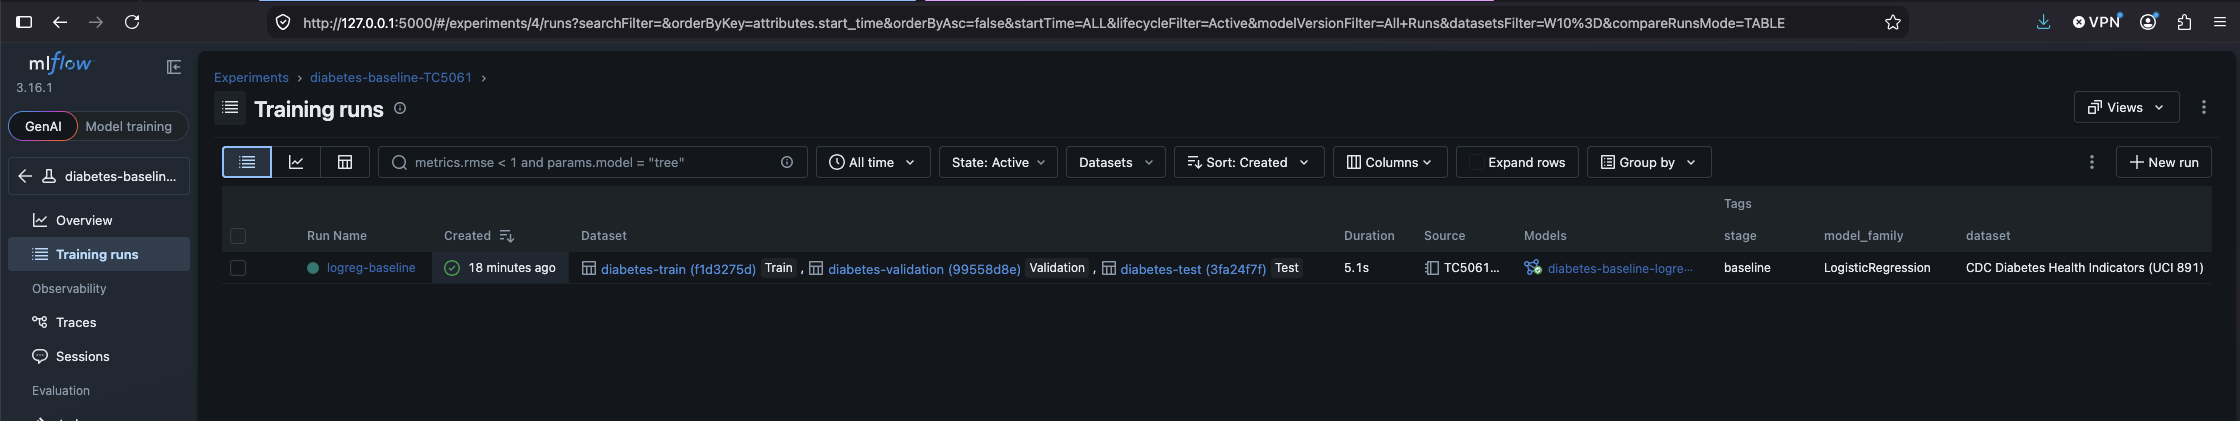

Imagen 2 Training overview con sus respectivas columnas del modelo subidas a MlFlow:
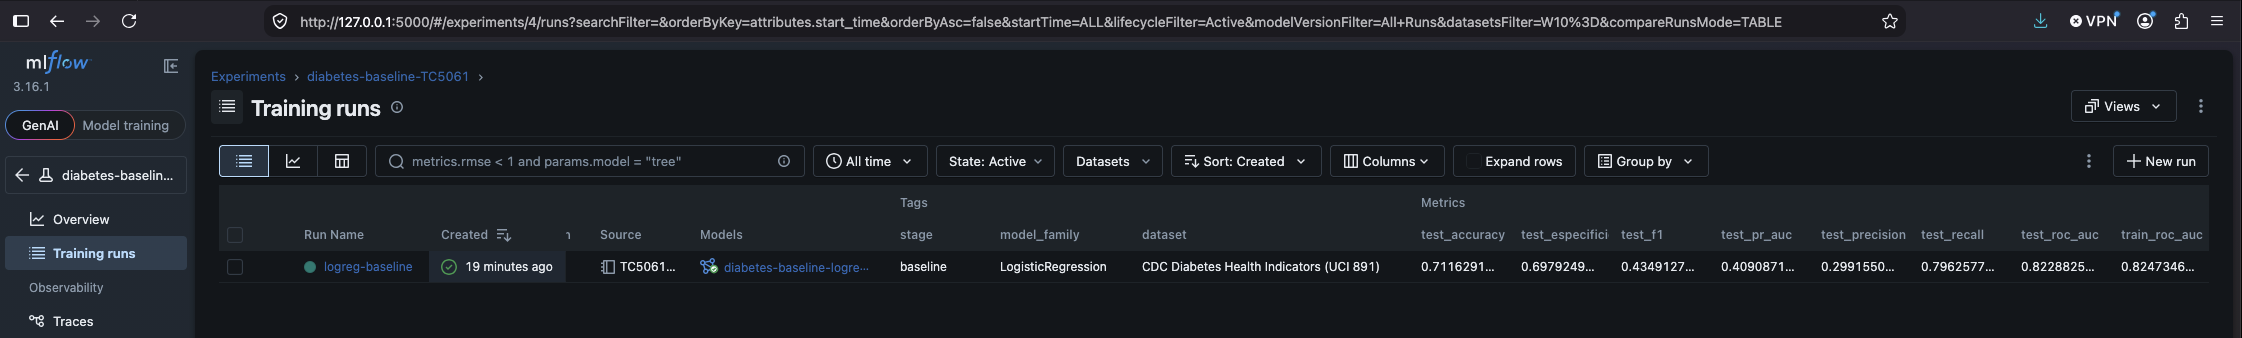

Imagen 3 Métricas, parámetros, tags, datasets y overview acerca de la corrida:
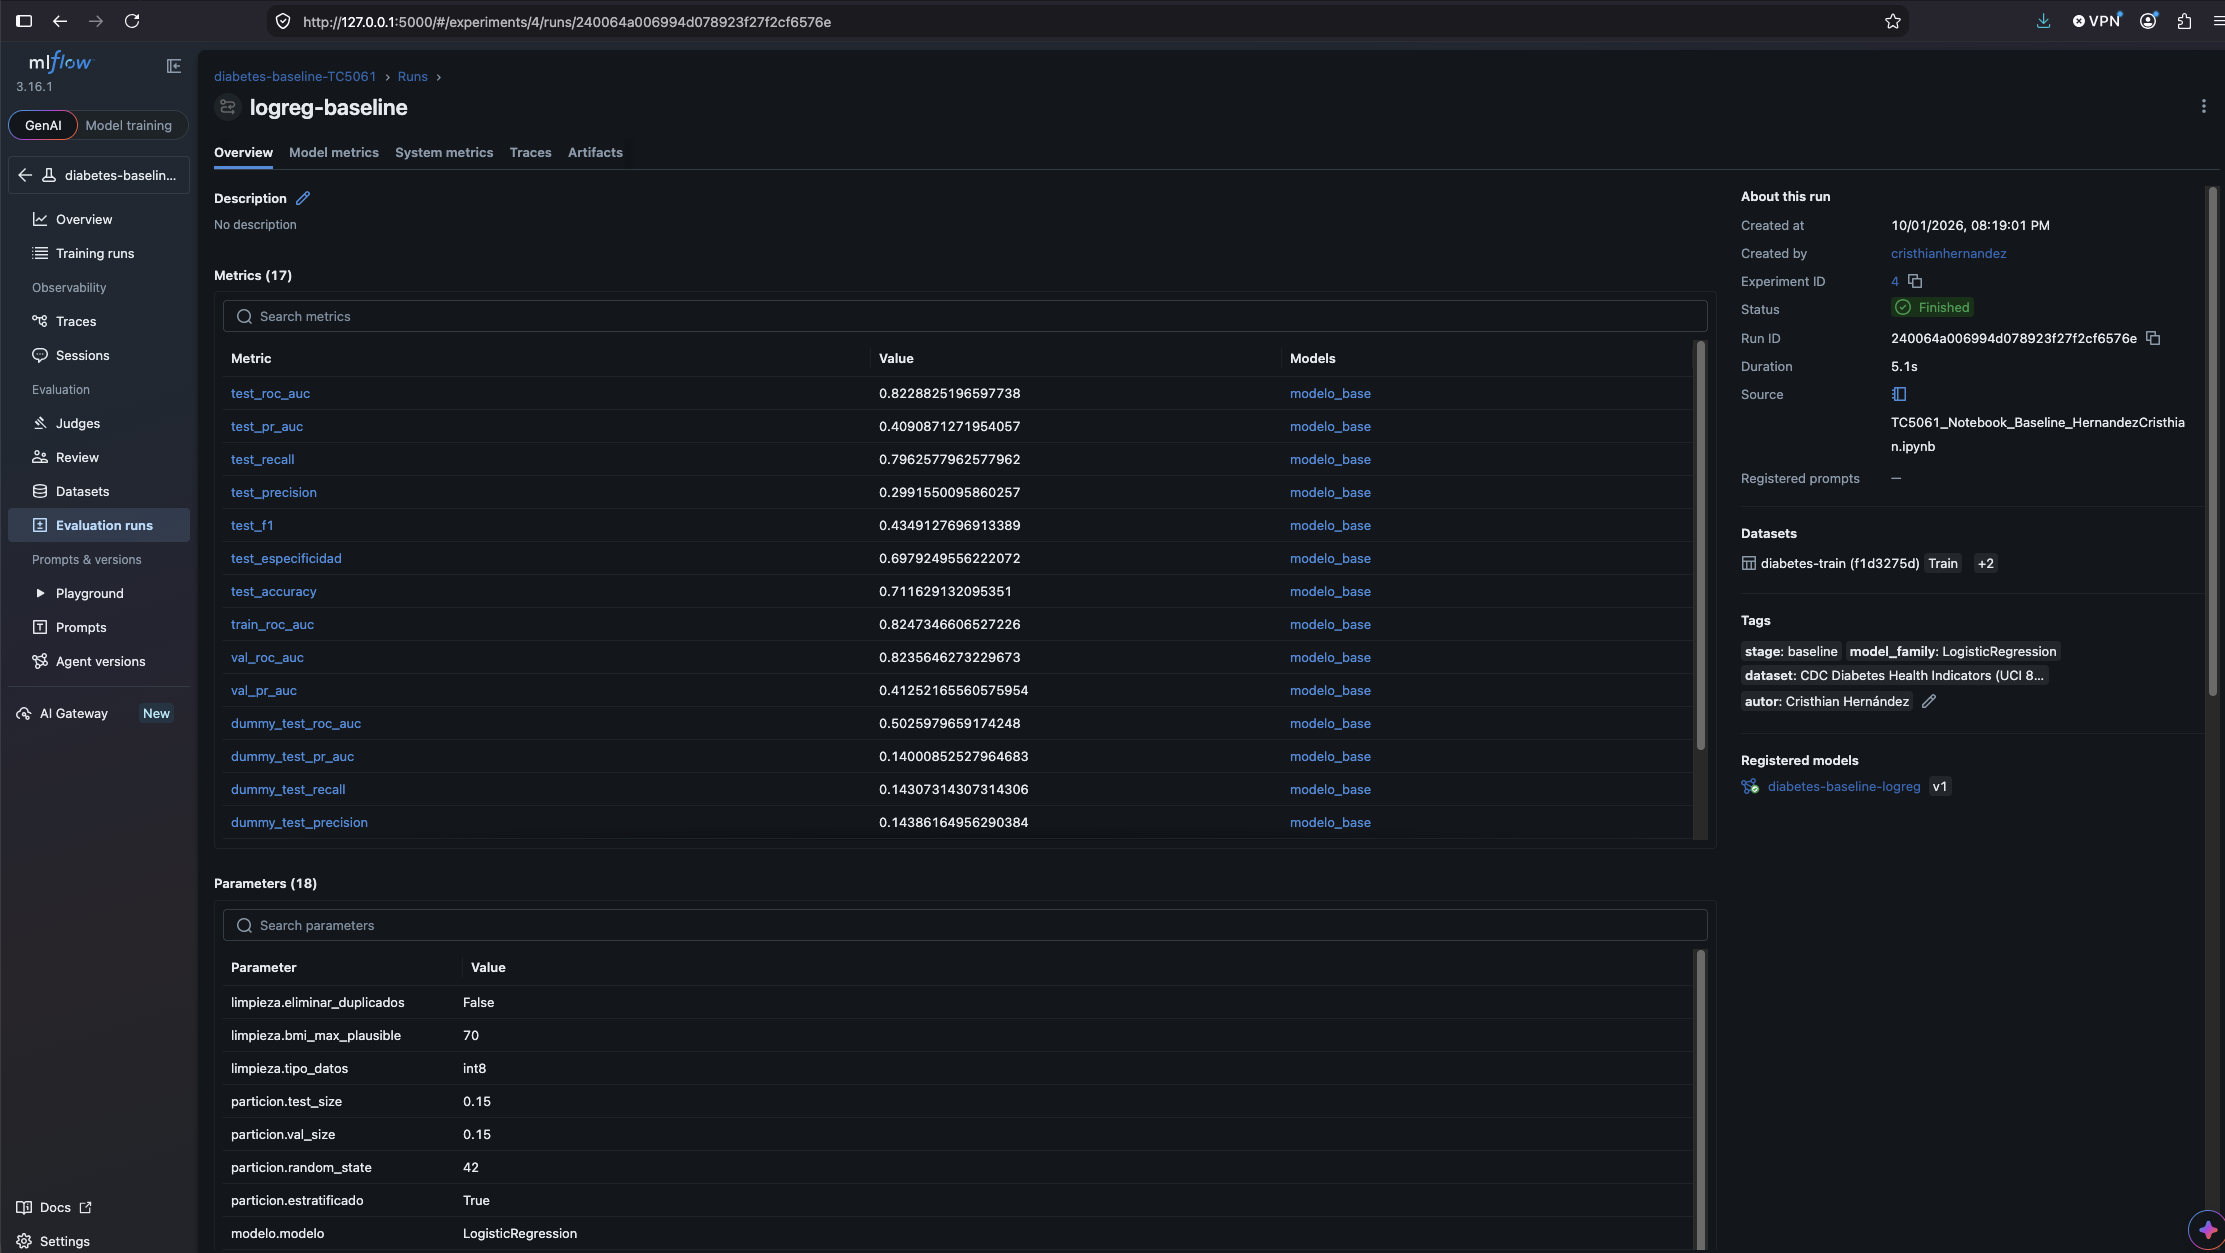

Imagen 4 Artefactos del modelo base subidos a MLFlow ejemplos mostrando curva roc y curva precision y recall:
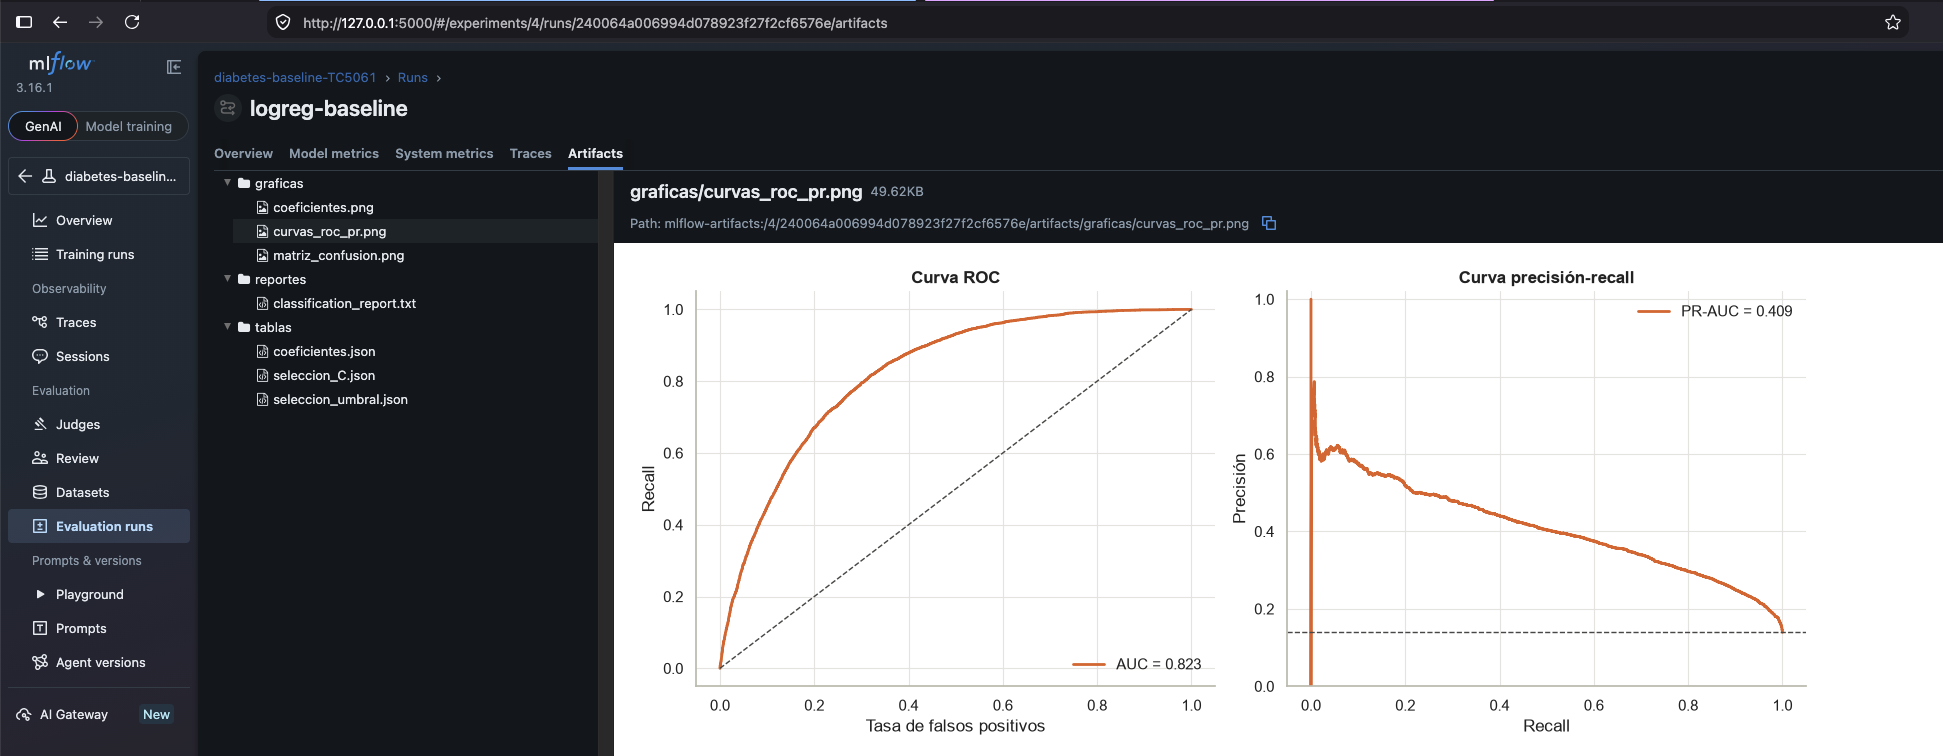

Imagen 5 Artefactos del modelo base subidos a MLFlow ejemplos mostrando matriz de confusión:
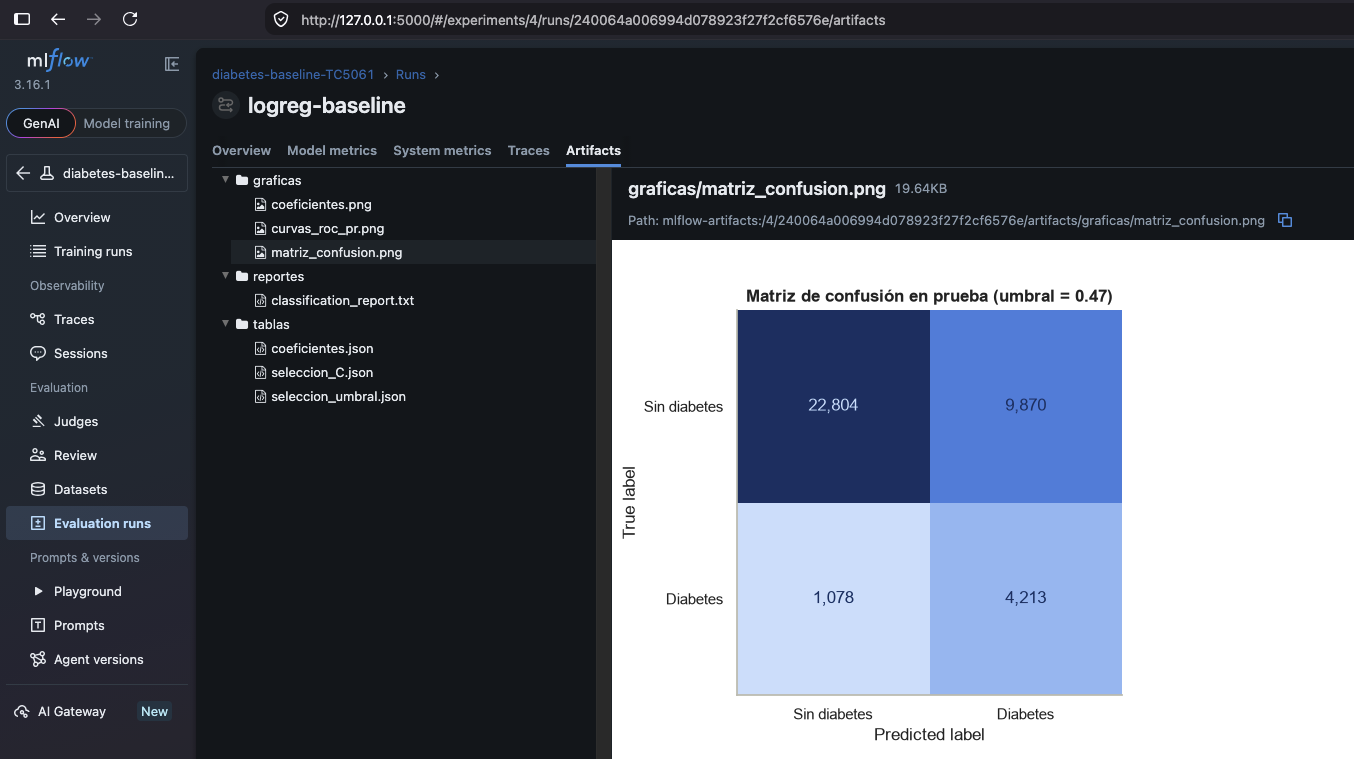


## Paso 7: Redacta una reflexión:

Al final del notebook, explica brevemente qué mejorarías en este flujo aplicando prácticas de MLOps y por qué.
¿Cómo se ven reflejados estos aprendizajes dentro de tu área profesional?
150 palabras o más de extensión.

### 7.1 ¿Qué mejoraría en este flujo aplicando prácticas de MLOps?

Este notebook cumple su objetivo como experimento: el baseline es reproducible, está documentado y quedó registrado en MLflow con sus parámetros, métricas, datos y modelo. Sin embargo, todavía es un flujo **manual y lineal** que depende de que una persona ejecute las celdas en orden. Para llevarlo a un entorno productivo haría cuatro mejoras:

1. **Pasar del notebook a un pipeline modular.** Separaría la carga, la limpieza, el entrenamiento y la evaluación en módulos de Python con pruebas unitarias (por ejemplo, para `limpiar_datos`) y los orquestaría como pasos independientes. El notebook es ideal para explorar, pero mezcla estado oculto con lógica: durante este trabajo, guardar una versión vieja del archivo desde el editor llegó a borrar código ya escrito. Un pipeline versionado en Git evita ese tipo de fragilidad.

2. **Versionar los datos, no solo el código.** Hoy el dataset se descarga en vivo desde UCI en cada ejecución; si la fuente cambia, el experimento deja de ser reproducible aunque el código sea el mismo. Guardaría una copia del dataset  en un almacenamiento de objetos y registraría su *hash* en MLflow.

3. **Empaquetar la lógica de decisión y automatizar la promoción del modelo.** El umbral de 0.47 vive fuera del modelo registrado. Lo incluiría en un modelo `pyfunc` y usaría *aliases* del Model Registry (`champion` / `challenger`) con una regla de promoción automática en CI/CD: un modelo nuevo solo se promueve si supera **ROC-AUC = 0.823 y PR-AUC = 0.409** en el mismo conjunto de prueba y si mantiene un recall similar entre grupos de `Sex` e `Income`.

4. **Monitorear el modelo en producción.** Vigilaría el *drift* de las variables con más peso (`GenHlth`, `BMI`, `Age`), la prevalencia de las predicciones positivas y, cuando haya etiquetas reales, el recall. El EDA mostró que la población está cargada hacia ciertos grupos; si esa composición cambia, el desempeño también cambiará, y debe detectarse antes de que afecte decisiones.

### 7.2 ¿Cómo se reflejan estos aprendizajes en mi área profesional?

Como *Senior Data Systems Software Engineer*, mi trabajo consiste en construir sistemas de datos confiables: pipelines idempotentes, esquemas con contratos claros, despliegues automatizados y observabilidad. Este ejercicio me mostró que **un modelo de machine learning es un componente más de esos sistemas**, con una diferencia importante: su comportamiento depende tanto del código como de los datos con los que se entrenó.

Por eso, muchas prácticas que ya aplico tienen un equivalente directo en MLOps. El esquema de validación es un **contrato de datos**; MLflow cumple para los modelos el papel que Git y un registro de artefactos cumplen para el software; la regla de promoción con métricas mínimas es un *quality gate* de CI/CD, y el monitoreo de *drift* es el equivalente a los SLO que ya definimos para los servicios.

El aprendizaje más valioso fue entender que **las decisiones de datos son decisiones de producto**. Conservar los duplicados, eliminar BMI > 70 o elegir un umbral que priorice el recall cambian el comportamiento del sistema tanto como cualquier línea de código, así que deben quedar documentadas, versionadas y trazables. En mi trabajo, esto se traduce en diseñar plataformas donde esa trazabilidad no dependa de la disciplina de cada persona, sino que esté integrada en la infraestructura desde el inicio. También me mostró que comprender las reglas de negocio detrás de cada decisión es parte del trabajo técnico, lo que vuelve este aprendizaje interdisciplinario.

---

**Declaración de uso de inteligencia artificial:** En la elaboración de esta actividad se utilizó Claude (Anthropic, 2026) como apoyo para verificar la precisión técnica y la redacción de los textos, estructurar las celdas markdown del notebook y sugerir qué visualizaciones incluir. El análisis, la selección de los modelos, métricas, implementación, la ejecución del código y la interpretación de los resultados fueron realizados por el alumno, que revisó y validó todo el contenido generado.

### Bibliografía:

Anthropic. (2026). Claude (versión Opus 5.5) [Modelo de lenguaje de gran tamaño]. https://claude.ai

Centers for Disease Control and Prevention. (2017). CDC Diabetes Health Indicators [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C53919

Géron, A. (2019). *Hands-on Machine Learning with Scikit-Learn, Keras and TensorFlow* (2.ª ed.). O’Reilly Media.

Lauchande, N. (2021). Machine Learning Engineering with MLFlow. Packt Publishing.

MLflow. (s.f.). *MLflow Tracking*. Recuperado el 30 de septiembre de 2026, de https://mlflow.org/docs/latest/tracking.html

Treveil, M., Omont, N., Stenac, C., Lefevre, K., Phan, D., Zentici, J., Lavoillotte, A., Miyazaki, M., & Heidmann, L. (2020). Introducing MLOps: How to scale machine learning in the enterprise. O’Reilly Media.
